# Phase 0: Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Show all columns when print a DataFrame
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

# Keep plots clean and readable
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
base_path = "/content/drive/MyDrive/EDA_Loan_Project/"

app_path = base_path + "application_data.csv"
prev_path = base_path + "previous_application.csv"
desc_path = base_path + "columns_description.csv"

In [ ]:
import os

for path in [app_path, prev_path, desc_path]:
    print(path, "->", os.path.exists(path))

/content/drive/MyDrive/EDA_Loan_Project/application_data.csv -> True
/content/drive/MyDrive/EDA_Loan_Project/previous_application.csv -> True
/content/drive/MyDrive/EDA_Loan_Project/columns_description.csv -> True


In [ ]:
app_raw = pd.read_csv(app_path)
prev_raw = pd.read_csv(prev_path)

try:
    desc = pd.read_csv(desc_path)
except UnicodeDecodeError:
    desc = pd.read_csv(desc_path, encoding="latin-1")

In [ ]:
# Work on copies. The raw data stays untouched.
app_df = app_raw.copy()
prev_df = prev_raw.copy()

In [ ]:
print("application_data shape:", app_df.shape)
print("previous_application shape:", prev_df.shape)
print("columns_description shape:", desc.shape)

application_data shape: (307511, 122)
previous_application shape: (1670214, 37)
columns_description shape: (160, 5)


In [ ]:
desc.head(10)

,Unnamed: 0,Table,Row,Description,Special
0,1,application_data,SK_ID_CURR,ID of loan in our sample,NaN
1,2,application_data,TARGET,Target variable (1 - client with payment diffi...,NaN
2,5,application_data,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
3,6,application_data,CODE_GENDER,Gender of the client,NaN
4,7,application_data,FLAG_OWN_CAR,Flag if the client owns a car,NaN
5,8,application_data,FLAG_OWN_REALTY,Flag if client owns a house or flat,NaN
6,9,application_data,CNT_CHILDREN,Number of children the client has,NaN
7,10,application_data,AMT_INCOME_TOTAL,Income of the client,NaN
8,11,application_data,AMT_CREDIT,Credit amount of the loan,NaN
9,12,application_data,AMT_ANNUITY,Loan annuity,NaN


### Phase 0 Outputs: Dataset Overview

1. `application_data` contains 307,511 rows and 122 columns. Each row represents one loan application.

2. `previous_application` contains 1,670,214 rows and 37 columns. This is approximately 5.4 records per client on average if both datasets contain the same clients. We must verify this using `SK_ID_CURR`.

3. `columns_description` contains 160 rows and 5 columns. This exceeds the combined 159 columns in the two main datasets. We must inspect the dictionary to identify any extra rows or entries.

4. The dictionary contains an extra column, `Unnamed: 0`, which appears to be an old row index. We can exclude it from the analysis if it has no useful information.

5. The data dictionary identifies `SK_ID_CURR` as the client ID and `TARGET` as the target variable. `TARGET = 1` indicates payment difficulties, while `TARGET = 0` indicates no recorded payment difficulties.

# Phase 1: Understand the data

In [ ]:
# Inspect application_data

app_df.info(verbose=False)
app_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [ ]:
# Inspect previous_application

prev_df.info(verbose=False)
prev_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1670214 entries, 0 to 1670213
Columns: 37 entries, SK_ID_PREV to NFLAG_INSURED_ON_APPROVAL
dtypes: float64(15), int64(6), object(16)
memory usage: 471.5+ MB


,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,RATE_DOWN_PAYMENT,RATE_INTEREST_PRIMARY,RATE_INTEREST_PRIVILEGED,NAME_CASH_LOAN_PURPOSE,NAME_CONTRACT_STATUS,DAYS_DECISION,NAME_PAYMENT_TYPE,CODE_REJECT_REASON,NAME_TYPE_SUITE,NAME_CLIENT_TYPE,NAME_GOODS_CATEGORY,NAME_PORTFOLIO,NAME_PRODUCT_TYPE,CHANNEL_TYPE,SELLERPLACE_AREA,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,Y,1,0.0,0.182832,0.867336,XAP,Approved,-73,Cash through the bank,XAP,NaN,Repeater,Mobile,POS,XNA,Country-wide,35,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-164,XNA,XAP,Unaccompanied,Repeater,XNA,Cash,x-sell,Contact center,-1,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-301,Cash through the bank,XAP,"Spouse, partner",Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0
3,2819243,176158,Cash loans,47041.335,450000.0,470790.0,NaN,450000.0,MONDAY,7,Y,1,NaN,NaN,NaN,XNA,Approved,-512,Cash through the bank,XAP,NaN,Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,12.0,middle,Cash X-Sell: middle,365243.0,-482.0,-152.0,-182.0,-177.0,1.0
4,1784265,202054,Cash loans,31924.395,337500.0,404055.0,NaN,337500.0,THURSDAY,9,Y,1,NaN,NaN,NaN,Repairs,Refused,-781,Cash through the bank,HC,NaN,Repeater,XNA,Cash,walk-in,Credit and cash offices,-1,XNA,24.0,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Check the target column

print(app_df["TARGET"].value_counts())
print()
print(app_df["TARGET"].value_counts(normalize=True) * 100)

TARGET
0    282686
1     24825
Name: count, dtype: int64

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


`value_counts()` counts each unique value. `normalize=True` returns proportions. Multiplying by 100 converts the proportions into percentages.

In [ ]:
# Check duplicates

print("Duplicate rows in application_data:", app_df.duplicated().sum())
print("Duplicate SK_ID_CURR in application_data:", app_df["SK_ID_CURR"].duplicated().sum())
print("Duplicate rows in previous_application:", prev_df.duplicated().sum())

Duplicate rows in application_data: 0
Duplicate SK_ID_CURR in application_data: 0
Duplicate rows in previous_application: 0


We check `SK_ID_CURR` because each client should have only one row in `application_data`. A full row can be unique even when the client ID is duplicated. The duplicate count for `SK_ID_CURR` should be 0.

In [ ]:
# Check how clients link across files

n_clients_app = app_df["SK_ID_CURR"].nunique()
n_clients_prev = prev_df["SK_ID_CURR"].nunique()
n_common = len(set(app_df["SK_ID_CURR"]) & set(prev_df["SK_ID_CURR"]))

print("Unique clients in application_data:", n_clients_app)
print("Unique clients in previous_application:", n_clients_prev)
print("Clients in both files:", n_common)
print("Average previous loans per client:", round(len(prev_df) / n_clients_prev, 2))

Unique clients in application_data: 307511
Unique clients in previous_application: 338857
Clients in both files: 291057
Average previous loans per client: 4.93


This tells us how many current applicants have a loan history. Clients without history are the “limited or no credit history” group from your business case.

In [ ]:
## Sort columns by type

# Identifier columns
id_cols = ["SK_ID_CURR"]

# Numerical and categorical columns in application_data
num_cols = app_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = app_df.select_dtypes(include=["object"]).columns.tolist()

# Remove ID and target from the numerical list
num_cols = [c for c in num_cols if c not in id_cols + ["TARGET"]]

print("Numerical columns:", len(num_cols))
print("Categorical columns:", len(cat_cols))
print()
print(cat_cols)


Numerical columns: 104
Categorical columns: 16

['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


Important: this step only sorts by data type. Some numerical columns are really flags (0 or 1) or small-count categories

In [ ]:
## Find flag and low-cardinality columns

# Count unique values in each numerical column
unique_counts = app_df[num_cols].nunique().sort_values()

# Columns with 2 unique values are flags
flag_cols = unique_counts[unique_counts <= 2].index.tolist()

print("Flag columns:", len(flag_cols))
print(flag_cols)

Flag columns: 32
['FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_MOBIL', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'FLAG_EMAIL', 'REG_REGION_NOT_LIVE_REGION', 'REG_CITY_NOT_LIVE_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'REG_CITY_NOT_WORK_CITY', 'FLAG_DOCUMENT_20', 'FLAG_DOCUMENT_21', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_4', 'FLAG_DOCUMENT_5', 'FLAG_DOCUMENT_6', 'FLAG_DOCUMENT_7', 'FLAG_DOCUMENT_8', 'FLAG_DOCUMENT_9', 'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_11', 'FLAG_DOCUMENT_12', 'FLAG_DOCUMENT_13', 'FLAG_DOCUMENT_14', 'FLAG_DOCUMENT_15', 'FLAG_DOCUMENT_16', 'FLAG_DOCUMENT_17', 'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_3']


Why: a 0/1 flag should be treated as a category, not as a continuous number

In [ ]:
# Check the dictionary extra row

desc[desc["Table"].isna() | desc["Row"].isna()]

,Unnamed: 0,Table,Row,Description,Special


This shows any row in the dictionary with a missing table or column name. It explains the 160 versus 159 difference.

## Phase 1 Outputs

1. Target imbalance: 282,686 clients (91.93%) have no recorded payment difficulties, while 24,825 clients (8.07%) have payment difficulties. The ratio is approximately 11.4:1. We will examine this imbalance further in the relevant phase.

2. No duplicates: Both datasets contain zero duplicate rows. `SK_ID_CURR` is also unique in `application_data`, confirming that each client has only one current application record.

3. Client overlap: 291,057 clients appear in both datasets. Therefore, 16,454 applicants (about 5.4%) have no matching previous application record. These applicants may belong to the no-credit-history group in the business case.

4. Corrected average: `previous_application` contains an average of 4.93 records per client, based on the calculation in your output. Use 4.93 instead of the earlier estimate of 5.4.

5. Extra clients: `previous_application` contains 338,857 unique clients, exceeding the number in `application_data`. Approximately 47,800 clients have previous application records but no current application record. These clients will be excluded from a standard inner join.

6. Column types: The dataset contains 104 numerical columns, including 32 flag variables, leaving approximately 72 other numerical variables. Of the 16 categorical columns, `FLAG_OWN_CAR` and `FLAG_OWN_REALTY` represent Y/N flags and may be treated as binary variables.


# Phase 2: Missing values and data cleaning

In [ ]:
# Missing value table

def missing_table(df):
    """Return a table of missing counts and percentages, highest first."""
    miss_count = df.isna().sum()
    miss_pct = (miss_count / len(df) * 100).round(2)
    out = pd.DataFrame({"missing_count": miss_count, "missing_pct": miss_pct})
    return out[out["missing_count"] > 0].sort_values("missing_pct", ascending=False)

app_missing = missing_table(app_df)
prev_missing = missing_table(prev_df)

print("application_data: columns with missing values:", len(app_missing), "of", app_df.shape[1])
print("previous_application: columns with missing values:", len(prev_missing), "of", prev_df.shape[1])
app_missing.head(30)

application_data: columns with missing values: 67 of 122
previous_application: columns with missing values: 16 of 37


,missing_count,missing_pct
COMMONAREA_MEDI,214865,69.87
COMMONAREA_MODE,214865,69.87
COMMONAREA_AVG,214865,69.87
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_AVG,213514,69.43
FONDKAPREMONT_MODE,210295,68.39
LIVINGAPARTMENTS_AVG,210199,68.35
LIVINGAPARTMENTS_MEDI,210199,68.35
LIVINGAPARTMENTS_MODE,210199,68.35


In [ ]:
# See how bad it is at different cut-offs

for cutoff in [10, 20, 30, 40, 50, 60]:
    n_app = (app_missing["missing_pct"] > cutoff).sum()
    n_prev = (prev_missing["missing_pct"] > cutoff).sum()
    print(f"Above {cutoff}% missing -> application_data: {n_app} columns, previous_application: {n_prev} columns")

Above 10% missing -> application_data: 57 columns, previous_application: 14 columns
Above 20% missing -> application_data: 50 columns, previous_application: 14 columns
Above 30% missing -> application_data: 50 columns, previous_application: 11 columns
Above 40% missing -> application_data: 49 columns, previous_application: 11 columns
Above 50% missing -> application_data: 41 columns, previous_application: 4 columns
Above 60% missing -> application_data: 17 columns, previous_application: 2 columns


This shows how many columns each threshold would remove. We choose the threshold after we see the numbers.

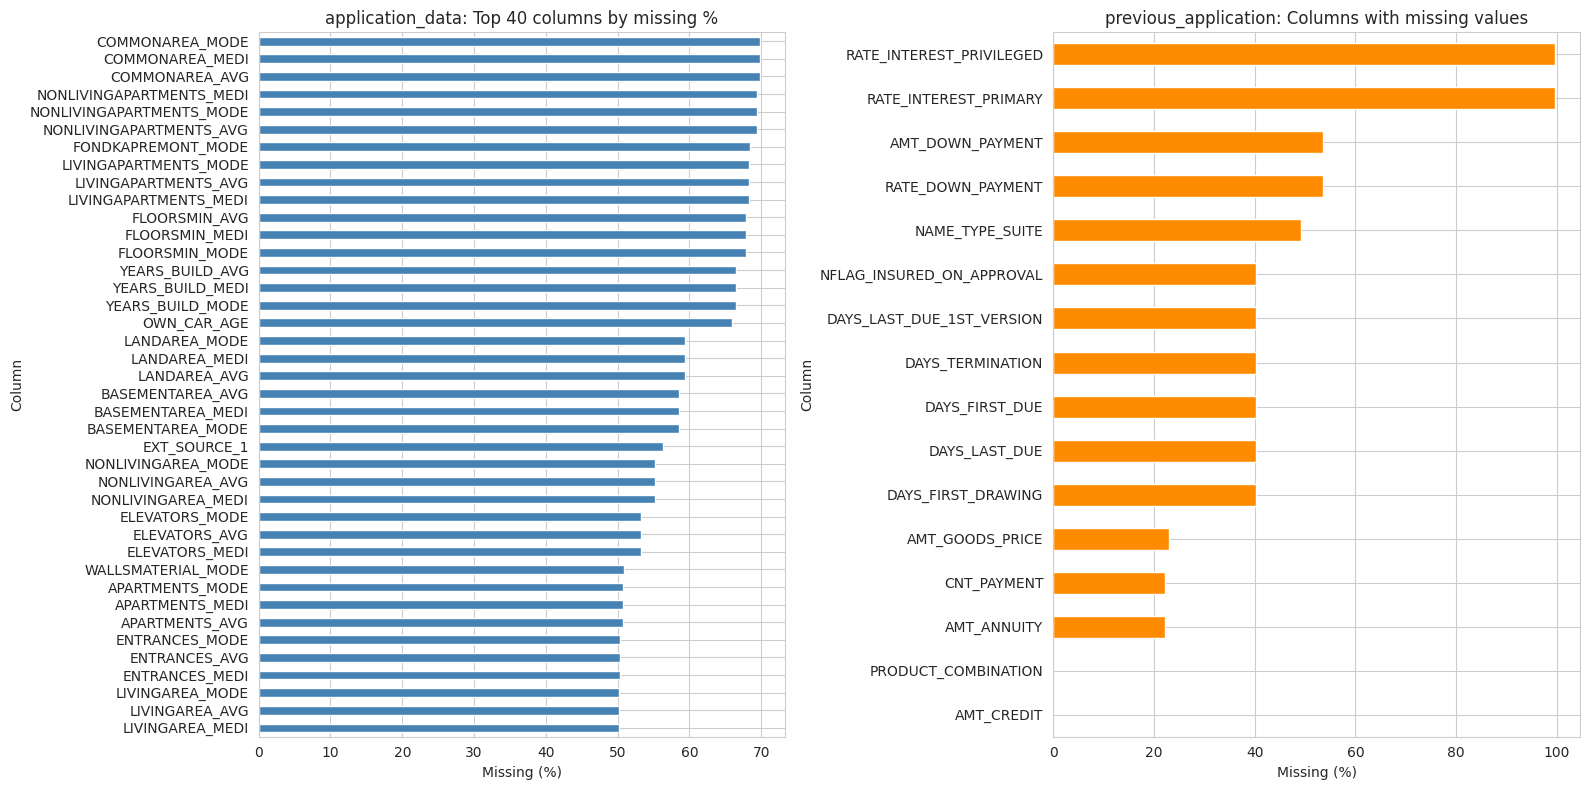

In [ ]:
# Plot missing percentages

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

app_missing.head(40)["missing_pct"].sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("application_data: Top 40 columns by missing %")
axes[0].set_xlabel("Missing (%)")
axes[0].set_ylabel("Column")

prev_missing["missing_pct"].sort_values().plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title("previous_application: Columns with missing values")
axes[1].set_xlabel("Missing (%)")
axes[1].set_ylabel("Column")

plt.tight_layout()
plt.show()

In [ ]:
## Look at the columns in the middle range

# Columns between 10% and 60% missing need a decision case by case
middle = app_missing[(app_missing["missing_pct"] >= 10) & (app_missing["missing_pct"] <= 60)]
print(len(middle), "columns between 10% and 60% missing")
middle

40 columns between 10% and 60% missing


,missing_count,missing_pct
LANDAREA_AVG,182590,59.38
LANDAREA_MEDI,182590,59.38
LANDAREA_MODE,182590,59.38
BASEMENTAREA_MODE,179943,58.52
BASEMENTAREA_MEDI,179943,58.52
BASEMENTAREA_AVG,179943,58.52
EXT_SOURCE_1,173378,56.38
NONLIVINGAREA_MEDI,169682,55.18
NONLIVINGAREA_AVG,169682,55.18
NONLIVINGAREA_MODE,169682,55.18


Why: columns at 70% missing or more are easy to drop. The middle range is where the real decisions happen.

In [ ]:
## Does missing mean something?

# Pick the columns in the middle range that are not building-related (you can edit this list)
check_cols = ["OCCUPATION_TYPE", "EXT_SOURCE_1", "EXT_SOURCE_3"]
check_cols = [c for c in check_cols if c in app_df.columns]

for col in check_cols:
    rate = app_df.groupby(app_df[col].isna())["TARGET"].mean() * 100
    print(col)
    print("Default rate when value is present:", round(rate[False], 2), "%")
    print("Default rate when value is missing:", round(rate[True], 2), "%")
    print()

OCCUPATION_TYPE
Default rate when value is present: 8.79 %
Default rate when value is missing: 6.51 %

EXT_SOURCE_1
Default rate when value is present: 7.5 %
Default rate when value is missing: 8.52 %

EXT_SOURCE_3
Default rate when value is present: 7.77 %
Default rate when value is missing: 9.31 %



Why: if the default rate differs between “present” and “missing”, the missing pattern carries information. Dropping that column would lose a signal. If the rates are equal, the missing values are less important.

In [ ]:
## Check odd values

# 1. Placeholder in DAYS_EMPLOYED
n_placeholder = (app_df["DAYS_EMPLOYED"] == 365243).sum()
print("DAYS_EMPLOYED = 365243 rows:", n_placeholder)
print("Max DAYS_EMPLOYED:", app_df["DAYS_EMPLOYED"].max())

# 2. "XNA" values in categorical columns
for col in cat_cols:
    n_xna = (app_df[col] == "XNA").sum()
    if n_xna > 0:
        print(f"{col}: {n_xna} rows with XNA")

# 3. Negative values in columns that should be positive
print("Negative DAYS_BIRTH share:", (app_df["DAYS_BIRTH"] < 0).mean().round(3))

DAYS_EMPLOYED = 365243 rows: 55374
Max DAYS_EMPLOYED: 365243
CODE_GENDER: 4 rows with XNA
ORGANIZATION_TYPE: 55374 rows with XNA
Negative DAYS_BIRTH share: 1.0


Why: 365243 days is about 1,000 years. It is a placeholder, not a real value. It must not go into an average. We will handle it in the cleaning step, after we see the count.

## Phase 2.1 Outputs

1. Dictionary check: No dictionary rows have blank table or column names. The 160 versus 159 row difference remains unexplained, but it does not block the analysis.

2. Missing values: 67 of 122 columns (about 55%) in `application_data` and 16 of 37 columns (about 43%) in `previous_application` contain missing values.

3. Missing-value cutoff: A 40% cutoff flags 49 columns in `application_data` (40.2%). The number of flagged columns stays at 50 between 20% and 30%, then drops to 49 at the 30% to 40% range. `OCCUPATION_TYPE` has 31.35% missing values, and no columns fall between 31.35% and 47.40%. Therefore, 40% is a reasonable cutoff for review, not an automatic deletion rule.

4. Missing-value patterns: Missing values are associated with different default rates. For `OCCUPATION_TYPE`, the rate is 6.51% when missing and 8.79% when present. For `EXT_SOURCE_1`, it is 8.52% versus 7.50%. For `EXT_SOURCE_3`, it is 9.31% versus 7.77%. These differences suggest that missingness may contain useful information.

5. Unusual values: `DAYS_EMPLOYED = 365243` appears in 55,374 rows (18.01%). `ORGANIZATION_TYPE = XNA` appears in the same number of rows, and Cell 28 confirms that they occur together. `CODE_GENDER = XNA` appears in only four rows. All `DAYS_BIRTH` values are negative because they represent days before the application date. We will convert them into positive age values in years.

### Decisions and Next Steps

1. Use a 40% missing-value cutoff to identify columns for review in `application_data`. Print the flagged columns before deciding whether to drop them.

2. Keep numeric missing values as `NaN` for now. Do not replace them with zero or the mean without justification.

3. Label missing `OCCUPATION_TYPE` values as `Unknown` to retain all rows and preserve the missingness pattern.

4. Review `EXT_SOURCE_1` (56.38% missing) because its missingness is associated with a different default rate. Review `OWN_CAR_AGE` (65.99% missing) because missing values may indicate that a client does not own a car.

5. Delay the missing-value cutoff decision for `previous_application`. Four columns have more than 50% missing values, and 11 have more than 40%. Check whether fields such as `DAYS_TERMINATION` are missing because they do not apply to certain loan statuses before dropping them.


# Phase 2: Read the missing value results

In [ ]:
# Check the dictionary

# Show the full text of each description (the default view cuts it short)
pd.set_option("display.max_colwidth", None)

print(desc["Table"].value_counts())
print()
desc[desc["Row"].isin(["EXT_SOURCE_1", "EXT_SOURCE_3", "OWN_CAR_AGE", "OCCUPATION_TYPE"])][["Table", "Row", "Description"]]

Table
application_data            122
previous_application.csv     38
Name: count, dtype: int64



,Table,Row,Description
21,application_data,OWN_CAR_AGE,Age of client's car
28,application_data,OCCUPATION_TYPE,What kind of occupation does the client have
41,application_data,EXT_SOURCE_1,Normalized score from external data source
43,application_data,EXT_SOURCE_3,Normalized score from external data source


In [ ]:
# Exact missing values in previous_application

print(prev_df.columns.tolist())
prev_missing

['SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'AMT_ANNUITY', 'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'FLAG_LAST_APPL_PER_CONTRACT', 'NFLAG_LAST_APPL_IN_DAY', 'RATE_DOWN_PAYMENT', 'RATE_INTEREST_PRIMARY', 'RATE_INTEREST_PRIVILEGED', 'NAME_CASH_LOAN_PURPOSE', 'NAME_CONTRACT_STATUS', 'DAYS_DECISION', 'NAME_PAYMENT_TYPE', 'CODE_REJECT_REASON', 'NAME_TYPE_SUITE', 'NAME_CLIENT_TYPE', 'NAME_GOODS_CATEGORY', 'NAME_PORTFOLIO', 'NAME_PRODUCT_TYPE', 'CHANNEL_TYPE', 'SELLERPLACE_AREA', 'NAME_SELLER_INDUSTRY', 'CNT_PAYMENT', 'NAME_YIELD_GROUP', 'PRODUCT_COMBINATION', 'DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION', 'NFLAG_INSURED_ON_APPROVAL']


,missing_count,missing_pct
RATE_INTEREST_PRIVILEGED,1664263,99.64
RATE_INTEREST_PRIMARY,1664263,99.64
AMT_DOWN_PAYMENT,895844,53.64
RATE_DOWN_PAYMENT,895844,53.64
NAME_TYPE_SUITE,820405,49.12
DAYS_LAST_DUE,673065,40.30
DAYS_FIRST_DRAWING,673065,40.30
DAYS_FIRST_DUE,673065,40.30
DAYS_TERMINATION,673065,40.30
NFLAG_INSURED_ON_APPROVAL,673065,40.30


In [ ]:
## Is the missing pattern tied to the loan outcome?

# Share of missing DAYS_TERMINATION values within each loan outcome
miss_by_status = (
    prev_df.groupby("NAME_CONTRACT_STATUS")["DAYS_TERMINATION"]
    .apply(lambda s: s.isna().mean() * 100)
)
print(miss_by_status.round(1))

NAME_CONTRACT_STATUS
Approved          3.8
Canceled        100.0
Refused         100.0
Unused offer    100.0
Name: DAYS_TERMINATION, dtype: float64


In [ ]:
## Is OWN_CAR_AGE missing because there is no car?

# Share of missing OWN_CAR_AGE for clients with (Y) and without (N) a car
print(
    app_df.groupby("FLAG_OWN_CAR")["OWN_CAR_AGE"]
    .apply(lambda s: s.isna().mean() * 100)
    .round(1)
)

FLAG_OWN_CAR
N    100.0
Y      0.0
Name: OWN_CAR_AGE, dtype: float64


In [ ]:
## Do EXT_SOURCE scores separate the two groups?

# Median score for non-defaulters (0) and defaulters (1). NaN is skipped.
print(app_df.groupby("TARGET")[["EXT_SOURCE_1", "EXT_SOURCE_3"]].median().round(3))

        EXT_SOURCE_1  EXT_SOURCE_3
TARGET                            
0              0.517         0.546
1              0.362         0.379


In [ ]:
# Who is in the 365243 group?

is_placeholder = app_df["DAYS_EMPLOYED"] == 365243
is_xna_org = app_df["ORGANIZATION_TYPE"] == "XNA"

print("Share of rows:", round(is_placeholder.mean() * 100, 2), "%")
print("Default rate, placeholder group:", round(app_df.loc[is_placeholder, "TARGET"].mean() * 100, 2), "%")
print("Default rate, all other rows:", round(app_df.loc[~is_placeholder, "TARGET"].mean() * 100, 2), "%")
print("Same rows as ORGANIZATION_TYPE = XNA:", (is_placeholder == is_xna_org).all())
print()
print(app_df.loc[is_placeholder, "NAME_INCOME_TYPE"].value_counts())
print()

# crosstab counts rows for each pair of values
print(pd.crosstab(is_placeholder, app_df["OCCUPATION_TYPE"].isna()))

Share of rows: 18.01 %
Default rate, placeholder group: 5.4 %
Default rate, all other rows: 8.66 %
Same rows as ORGANIZATION_TYPE = XNA: True

NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64

OCCUPATION_TYPE   False  True 
DAYS_EMPLOYED                 
False            211118  41019
True                  2  55372


In [ ]:
## Preview the drop list (no dropping yet)

cutoff = 40

app_drop = app_missing[app_missing["missing_pct"] > cutoff].index.tolist()
prev_drop = prev_missing[prev_missing["missing_pct"] > cutoff].index.tolist()

# The housing columns end with _AVG, _MODE, or _MEDI
housing_drop = [c for c in app_drop if c.endswith(("_AVG", "_MODE", "_MEDI"))]
other_drop = [c for c in app_drop if c not in housing_drop]

print("application_data columns above", cutoff, "% missing:", len(app_drop))
print("  Housing columns:", len(housing_drop))
print("  Other columns:", other_drop)
print()
print("previous_application columns above", cutoff, "% missing:", len(prev_drop))
print(prev_drop)

application_data columns above 40 % missing: 49
  Housing columns: 47
  Other columns: ['OWN_CAR_AGE', 'EXT_SOURCE_1']

previous_application columns above 40 % missing: 11
['RATE_INTEREST_PRIVILEGED', 'RATE_INTEREST_PRIMARY', 'AMT_DOWN_PAYMENT', 'RATE_DOWN_PAYMENT', 'NAME_TYPE_SUITE', 'DAYS_LAST_DUE', 'DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_TERMINATION', 'NFLAG_INSURED_ON_APPROVAL', 'DAYS_LAST_DUE_1ST_VERSION']


## Phase 2.2 Outputs

1. Dictionary mismatch: The data dictionary contains 122 rows for `application_data` and 38 rows for `previous_application.csv`, while the datasets contain 122 and 37 columns. The extra dictionary row explains the difference. The dictionary also uses `previous_application.csv` as its table label.

2. Structural missing values: `DAYS_TERMINATION` is missing for 100% of Canceled, Refused, and Unused offer loans, but only 3.8% of Approved loans. Missing values can indicate that a field does not apply to a particular loan status. Six `DAYS_*` columns and `NFLAG_INSURED_ON_APPROVAL` also have 673,065 missing values each, although their patterns require further verification.

3. Category spelling: The dataset uses `Canceled` with one L. We must use this exact spelling in code.

4. Car ownership: `OWN_CAR_AGE` is missing for 100% of clients without a car and 0% of car owners. These missing values are structural because car age does not apply to clients without a car.

5. External scores: Non-defaulters have higher median external scores than defaulters. For `EXT_SOURCE_1`, the medians are 0.517 and 0.362, respectively. For `EXT_SOURCE_3`, they are 0.546 and 0.379. Lower scores are associated with higher default rates, making these variables useful for further analysis.

6. Employment placeholder: `DAYS_EMPLOYED = 365243` appears in 55,374 rows (18.01%). Of these, 55,352 are Pensioners and 22 are Unemployed. This group has a 5.4% default rate, compared with 8.66% for all other rows. It also matches `ORGANIZATION_TYPE = XNA` exactly.

7. Occupation missingness: Of the 96,391 missing `OCCUPATION_TYPE` values, 55,372 belong to the placeholder group. This represents 57.4% of all missing occupation values. The lower default rate among clients with missing occupation data is therefore largely associated with pensioners, who have a lower default rate.

8. Housing columns: The proposed drop list contains 47 housing-related columns, plus `OWN_CAR_AGE` and `EXT_SOURCE_1`. The 47 housing columns have more than 40% missing values and use three versions of similar measures: `_AVG`, `_MODE`, and `_MEDI`.

### Cleaning Decisions

#### `application_data`

1. Drop the 47 housing columns with more than 40% missing values. Their three versions contain overlapping information and may dominate the correlation analysis.

2. Keep `EXT_SOURCE_1` despite its 56.38% missing values because its scores distinguish between defaulters and non-defaulters.

3. Keep `OWN_CAR_AGE` despite its 65.99% missing values. Analyze this variable only for clients who own cars.

4. Replace missing `OCCUPATION_TYPE` values with `Unknown`. This preserves all 96,391 affected rows and keeps pensioners identifiable through `NAME_INCOME_TYPE`.

5. Replace `DAYS_EMPLOYED = 365243` with `NaN`. The value is a placeholder, not a valid employment duration.

6. Replace `ORGANIZATION_TYPE = XNA` with `Unknown`. This keeps the 55,374 affected rows identifiable in plots and summaries.

7. Replace `CODE_GENDER = XNA` with `NaN` for the four affected rows. Retain the rows to preserve the original target counts.

8. Leave the remaining numerical missing values as `NaN`. This includes `EXT_SOURCE_1`, `EXT_SOURCE_3`, `AMT_REQ_CREDIT_BUREAU_*`, and `OWN_CAR_AGE`.

#### `previous_application`

1. Drop the 11 columns with more than 40% missing values.

2. Exclude the two `RATE_INTEREST` columns because 99.64% of their values are missing.

3. Exclude the relevant `DAYS_*` and insurance columns because their values appear to depend on loan approval status.

4. Exclude the two down payment columns and `NAME_TYPE_SUITE`, which have more than 49% missing values. Their missingness patterns have not been confirmed as structural.

5. Retain `NAME_CONTRACT_STATUS` and loan amount variables because they support the analysis of previous loan outcomes and amounts.


# Phase 2: Decisions and cleaning

In [ ]:
## Two checks

# Check 1: find the extra dictionary row
dict_prev = desc[desc["Table"] == "previous_application.csv"]["Row"]
print("In dictionary but not in data:", sorted(set(dict_prev) - set(prev_df.columns)))
print("In data but not in dictionary:", sorted(set(prev_df.columns) - set(dict_prev)))
print()

# Check 2: default rate of missing occupation, split by placeholder group
# (needs is_placeholder from Cell 29)
miss_occ = app_df["OCCUPATION_TYPE"].isna()
print("Occupation present:", round(app_df.loc[~miss_occ, "TARGET"].mean() * 100, 2), "%")
print("Occupation missing, placeholder group:", round(app_df.loc[miss_occ & is_placeholder, "TARGET"].mean() * 100, 2), "%")
print("Occupation missing, other rows:", round(app_df.loc[miss_occ & ~is_placeholder, "TARGET"].mean() * 100, 2), "%")

In dictionary but not in data: ['NFLAG_MICRO_CASH', 'SK_ID_PREV ']
In data but not in dictionary: ['SK_ID_PREV']

Occupation present: 8.79 %
Occupation missing, placeholder group: 5.4 %
Occupation missing, other rows: 8.02 %


Dictionary mismatch: identifies two causes. `NFLAG_MICRO_CASH` appears in the dictionary but not in the dataset. `SK_ID_PREV ` has a trailing space in the dictionary, so it does not match `SK_ID_PREV` in the dataset. These explain the difference between 38 dictionary entries and 37 dataset columns. No dataset columns are missing.


In [ ]:
# Drop the housing columns

# Drop everything above 40% except the two columns we keep
keep_anyway = ["EXT_SOURCE_1", "OWN_CAR_AGE"]
app_drop_final = [c for c in app_drop if c not in keep_anyway]

print("Columns before:", app_df.shape[1])
app_df = app_df.drop(columns=app_drop_final)
print("Columns dropped:", len(app_drop_final))
print("Columns after:", app_df.shape[1])

Columns before: 122
Columns dropped: 47
Columns after: 75


In [ ]:
# Fill missing occupation

n_filled = app_df["OCCUPATION_TYPE"].isna().sum()
app_df["OCCUPATION_TYPE"] = app_df["OCCUPATION_TYPE"].fillna("Unknown")
print("OCCUPATION_TYPE values filled:", n_filled)

OCCUPATION_TYPE values filled: 96391


In [ ]:
# Handle the DAYS_EMPLOYED placeholder

n_placeholder = (app_df["DAYS_EMPLOYED"] == 365243).sum()
app_df["DAYS_EMPLOYED"] = app_df["DAYS_EMPLOYED"].replace(365243, np.nan)

print("Placeholder values replaced:", n_placeholder)
print("Missing DAYS_EMPLOYED now:", app_df["DAYS_EMPLOYED"].isna().sum())
print("Max DAYS_EMPLOYED now:", app_df["DAYS_EMPLOYED"].max())

Placeholder values replaced: 55374
Missing DAYS_EMPLOYED now: 55374
Max DAYS_EMPLOYED now: 0.0


In [ ]:
# Handle XNA values

n_org = (app_df["ORGANIZATION_TYPE"] == "XNA").sum()
app_df["ORGANIZATION_TYPE"] = app_df["ORGANIZATION_TYPE"].replace("XNA", "Unknown")

n_gender = (app_df["CODE_GENDER"] == "XNA").sum()
app_df["CODE_GENDER"] = app_df["CODE_GENDER"].replace("XNA", np.nan)

print("ORGANIZATION_TYPE XNA renamed:", n_org)
print("CODE_GENDER XNA set to NaN:", n_gender)

ORGANIZATION_TYPE XNA renamed: 55374
CODE_GENDER XNA set to NaN: 4


In [ ]:
# Clean previous_application

print("Columns before:", prev_df.shape[1])
prev_df = prev_df.drop(columns=prev_drop)
print("Columns dropped:", len(prev_drop))
print("Columns after:", prev_df.shape[1])

Columns before: 37
Columns dropped: 11
Columns after: 26


In [ ]:
# Refresh the column lists and verify

# The old lists still contain the dropped columns, so we update them
num_cols = [c for c in num_cols if c in app_df.columns]
cat_cols = [c for c in cat_cols if c in app_df.columns]
flag_cols = [c for c in flag_cols if c in app_df.columns]

print("app_df shape:", app_df.shape)
print("prev_df shape:", prev_df.shape)
print("Rows unchanged:", len(app_df) == len(app_raw))
print("Numerical:", len(num_cols), "| Categorical:", len(cat_cols), "| Flags:", len(flag_cols))
print()
missing_table(app_df)

app_df shape: (307511, 75)
prev_df shape: (1670214, 26)
Rows unchanged: True
Numerical: 61 | Categorical: 12 | Flags: 32



,missing_count,missing_pct
OWN_CAR_AGE,202929,65.99
EXT_SOURCE_1,173378,56.38
EXT_SOURCE_3,60965,19.83
DAYS_EMPLOYED,55374,18.01
AMT_REQ_CREDIT_BUREAU_QRT,41519,13.50
AMT_REQ_CREDIT_BUREAU_YEAR,41519,13.50
AMT_REQ_CREDIT_BUREAU_MON,41519,13.50
AMT_REQ_CREDIT_BUREAU_HOUR,41519,13.50
AMT_REQ_CREDIT_BUREAU_DAY,41519,13.50
AMT_REQ_CREDIT_BUREAU_WEEK,41519,13.50


# Phase 2: Check results and finish cleaning

In [ ]:
## Convert DAYS columns to years

days_map = {
    "DAYS_BIRTH": "AGE_YEARS",
    "DAYS_EMPLOYED": "YEARS_EMPLOYED",
    "DAYS_REGISTRATION": "YEARS_REGISTERED",
    "DAYS_ID_PUBLISH": "YEARS_ID_PUBLISH",
    "DAYS_LAST_PHONE_CHANGE": "YEARS_LAST_PHONE_CHANGE",
}

# Step 1: check that no value is positive (they should all be 0 or below)
print("DAYS columns in app_df:", [c for c in app_df.columns if c.startswith("DAYS_")])
for old in days_map:
    print(old, "max:", app_df[old].max())

# Step 2: convert days to years (divide by 365, flip the sign)
for old, new in days_map.items():
    app_df[new] = -app_df[old] / 365

# Step 3: drop the old columns
app_df = app_df.drop(columns=list(days_map))

# Step 4: update the numeric column list
num_cols = [c for c in num_cols if c not in days_map] + list(days_map.values())

print()
print("app_df shape:", app_df.shape)
app_df[list(days_map.values())].describe().round(2)

DAYS columns in app_df: ['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']
DAYS_BIRTH max: -7489
DAYS_EMPLOYED max: 0.0
DAYS_REGISTRATION max: 0.0
DAYS_ID_PUBLISH max: 0
DAYS_LAST_PHONE_CHANGE max: 0.0

app_df shape: (307511, 75)


,AGE_YEARS,YEARS_EMPLOYED,YEARS_REGISTERED,YEARS_ID_PUBLISH,YEARS_LAST_PHONE_CHANGE
count,307511.00,252137.00,307511.00,307511.00,307510.00
mean,43.94,6.53,13.66,8.20,2.64
std,11.96,6.41,9.65,4.14,2.27
min,20.52,-0.00,-0.00,0.00,-0.00
25%,34.01,2.10,5.51,4.71,0.75
50%,43.15,4.52,12.34,8.92,2.07
75%,53.92,8.70,20.49,11.78,4.30
max,69.12,49.07,67.59,19.72,11.76


In [ ]:
## Create groups and a ratio

print("Min income:", app_df["AMT_INCOME_TOTAL"].min())
print("Min credit:", app_df["AMT_CREDIT"].min())

# Age groups
app_df["AGE_GROUP"] = pd.cut(
    app_df["AGE_YEARS"],
    bins=[0, 30, 40, 50, 60, 100],
    labels=["Under 30", "30-39", "40-49", "50-59", "60+"],
    right=False,
)

# Income groups
app_df["INCOME_GROUP"] = pd.cut(
    app_df["AMT_INCOME_TOTAL"],
    bins=[0, 100000, 150000, 200000, 300000, np.inf],
    labels=["Up to 100K", "100K-150K", "150K-200K", "200K-300K", "Above 300K"],
)

# Credit amount groups
app_df["CREDIT_GROUP"] = pd.cut(
    app_df["AMT_CREDIT"],
    bins=[0, 250000, 500000, 750000, 1000000, np.inf],
    labels=["Up to 250K", "250K-500K", "500K-750K", "750K-1M", "Above 1M"],
)

# Credit to income ratio (needs income above 0)
app_df["CREDIT_INCOME_RATIO"] = app_df["AMT_CREDIT"] / app_df["AMT_INCOME_TOTAL"]
num_cols.append("CREDIT_INCOME_RATIO")

for col in ["AGE_GROUP", "INCOME_GROUP", "CREDIT_GROUP"]:
    print(col)
    print(app_df[col].value_counts(sort=False))
    print("Missing:", app_df[col].isna().sum())
    print()

Min income: 25650.0
Min credit: 45000.0
AGE_GROUP
AGE_GROUP
Under 30    45000
30-39       82299
40-49       76543
50-59       68074
60+         35595
Name: count, dtype: int64
Missing: 0

INCOME_GROUP
INCOME_GROUP
Up to 100K    63698
100K-150K     91591
150K-200K     64307
200K-300K     65176
Above 300K    22739
Name: count, dtype: int64
Missing: 0

CREDIT_GROUP
CREDIT_GROUP
Up to 250K    59198
250K-500K     90135
500K-750K     65094
750K-1M       43099
Above 1M      49985
Name: count, dtype: int64
Missing: 0



In [ ]:
## Choose the continuous columns for outlier checks

# Continuous means: not a flag, and more than 20 unique values
cont_cols = [c for c in num_cols if c not in flag_cols and app_df[c].nunique() > 20]
left_out = [c for c in num_cols if c not in flag_cols and c not in cont_cols]

print("Continuous columns:", len(cont_cols))
print(cont_cols)
print()
print("Numeric columns left out (small counts or ratings):", left_out)

Continuous columns: 20
['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'OWN_CAR_AGE', 'HOUR_APPR_PROCESS_START', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'OBS_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_YEAR', 'AGE_YEARS', 'YEARS_EMPLOYED', 'YEARS_REGISTERED', 'YEARS_ID_PUBLISH', 'YEARS_LAST_PHONE_CHANGE', 'CREDIT_INCOME_RATIO']

Numeric columns left out (small counts or ratings): ['CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'DEF_30_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_QRT']


In [ ]:
# Find outliers with the IQR rule

def iqr_outliers(df, cols):
    """Count outliers per column using the 1.5 x IQR rule."""
    rows = []
    for col in cols:
        s = df[col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = ((s < low) | (s > high)).sum()
        rows.append({
            "column": col,
            "q1": q1, "q3": q3, "iqr": iqr,
            "lower": low, "upper": high,
            "max": s.max(),
            "n_outliers": n_out,
            "pct_outliers": round(n_out / len(s) * 100, 2),
            "skew": round(s.skew(), 2),
        })
    return pd.DataFrame(rows).sort_values("pct_outliers", ascending=False)

outlier_table = iqr_outliers(app_df, cont_cols)
outlier_table.round(2)

,column,q1,q3,iqr,lower,upper,max,n_outliers,pct_outliers,skew
12,AMT_REQ_CREDIT_BUREAU_MON,0.00,0.00,0.00,0.00,0.00,2.700000e+01,43759,16.45,7.80
10,OBS_30_CNT_SOCIAL_CIRCLE,0.00,2.00,2.00,-3.00,5.00,3.480000e+02,19971,6.52,12.14
11,OBS_60_CNT_SOCIAL_CIRCLE,0.00,2.00,2.00,-3.00,5.00,3.440000e+02,19564,6.38,12.07
15,YEARS_EMPLOYED,2.10,8.70,6.60,-7.79,18.59,4.907000e+01,15149,6.01,1.97
3,AMT_GOODS_PRICE,238500.00,679500.00,441000.00,-423000.00,1341000.00,4.050000e+06,14728,4.79,1.35
5,OWN_CAR_AGE,5.00,15.00,10.00,-10.00,30.00,9.100000e+01,4932,4.72,2.75
0,AMT_INCOME_TOTAL,112500.00,202500.00,90000.00,-22500.00,337500.00,1.170000e+08,14035,4.56,391.56
19,CREDIT_INCOME_RATIO,2.02,5.16,3.14,-2.69,9.87,8.474000e+01,11510,3.74,1.84
4,REGION_POPULATION_RELATIVE,0.01,0.03,0.02,-0.02,0.06,7.000000e-02,8412,2.74,1.49
2,AMT_ANNUITY,16524.00,34596.00,18072.00,-10584.00,61704.00,2.580255e+05,7504,2.44,1.58


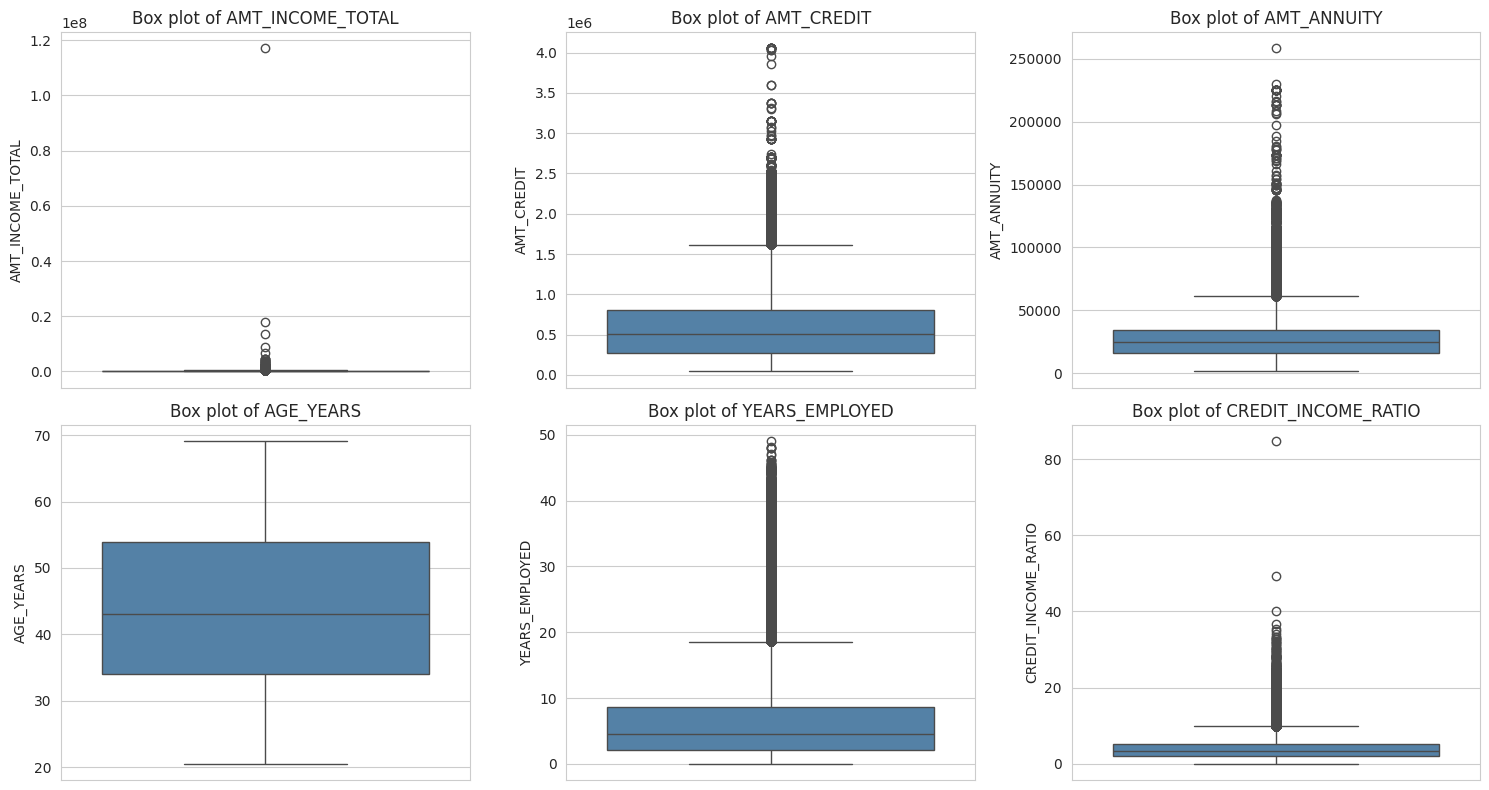

In [ ]:
# Box plots for key columns

plot_cols = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
             "AGE_YEARS", "YEARS_EMPLOYED", "CREDIT_INCOME_RATIO"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), plot_cols):
    sns.boxplot(y=app_df[col], ax=ax, color="steelblue")
    ax.set_title(f"Box plot of {col}")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

In [ ]:
## Investigate before deciding

# Top 5 incomes
print(app_df["AMT_INCOME_TOTAL"].sort_values(ascending=False).head(5))
print()

# Default rate for income outliers versus the rest
upper = outlier_table.set_index("column").loc["AMT_INCOME_TOTAL", "upper"]
is_high_income = app_df["AMT_INCOME_TOTAL"] > upper

print("Income upper fence:", round(upper))
print("High income rows:", is_high_income.sum())
print("Default rate, high income:", round(app_df.loc[is_high_income, "TARGET"].mean() * 100, 2), "%")
print("Default rate, other rows:", round(app_df.loc[~is_high_income, "TARGET"].mean() * 100, 2), "%")
print()

# Largest values in a count column
print("Max OBS_30_CNT_SOCIAL_CIRCLE:", app_df["OBS_30_CNT_SOCIAL_CIRCLE"].max())
print(app_df["OBS_30_CNT_SOCIAL_CIRCLE"].sort_values(ascending=False).head(5).tolist())

12840     117000000.0
203693     18000090.0
246858     13500000.0
77768       9000000.0
131127      6750000.0
Name: AMT_INCOME_TOTAL, dtype: float64

Income upper fence: 337500
High income rows: 14035
Default rate, high income: 5.81 %
Default rate, other rows: 8.18 %

Max OBS_30_CNT_SOCIAL_CIRCLE: 348.0
[348.0, 47.0, 30.0, 30.0, 29.0]


In [ ]:
# Odd values in previous_application

# XNA and XAP usually mean "not applicable" in this dataset (we verify with counts)
prev_cat = prev_df.select_dtypes(include="object").columns

for col in prev_cat:
    n = prev_df[col].isin(["XNA", "XAP"]).sum()
    if n > 0:
        print(f"{col}: {n} rows ({n / len(prev_df) * 100:.1f}%)")

print()
print(prev_df["NAME_CONTRACT_STATUS"].value_counts())
print()
print("Rows where AMT_APPLICATION = 0:", (prev_df["AMT_APPLICATION"] == 0).sum())
print("Rows where AMT_CREDIT is missing:", prev_df["AMT_CREDIT"].isna().sum())

NAME_CONTRACT_TYPE: 346 rows (0.0%)
NAME_CASH_LOAN_PURPOSE: 1600579 rows (95.8%)
NAME_PAYMENT_TYPE: 627384 rows (37.6%)
CODE_REJECT_REASON: 1358337 rows (81.3%)
NAME_CLIENT_TYPE: 1941 rows (0.1%)
NAME_GOODS_CATEGORY: 950809 rows (56.9%)
NAME_PORTFOLIO: 372230 rows (22.3%)
NAME_PRODUCT_TYPE: 1063666 rows (63.7%)
NAME_SELLER_INDUSTRY: 855720 rows (51.2%)
NAME_YIELD_GROUP: 517215 rows (31.0%)

NAME_CONTRACT_STATUS
Approved        1036781
Canceled         316319
Refused          290678
Unused offer      26436
Name: count, dtype: int64

Rows where AMT_APPLICATION = 0: 392402
Rows where AMT_CREDIT is missing: 1


# Phase 2: Outliers and final cleaning checks

In [ ]:
## Check the extreme values

# 1. The row with the highest income
top_row = app_df["AMT_INCOME_TOTAL"].idxmax()
print(app_df.loc[top_row, ["AMT_INCOME_TOTAL", "AMT_CREDIT", "NAME_INCOME_TYPE",
                           "OCCUPATION_TYPE", "AGE_YEARS", "TARGET"]])
print()

# 2. How many rows have very large social circle counts
print("OBS_30 above 50:", (app_df["OBS_30_CNT_SOCIAL_CIRCLE"] > 50).sum())
print("OBS_60 above 50:", (app_df["OBS_60_CNT_SOCIAL_CIRCLE"] > 50).sum())
print()

# 3. Car age: a big spike at one value would suggest a placeholder
print("OWN_CAR_AGE above 60:", (app_df["OWN_CAR_AGE"] > 60).sum())
print(app_df["OWN_CAR_AGE"].value_counts().head(5))
print()

# 4. Work history that does not fit the age (NaN rows count as False)
print("YEARS_EMPLOYED above AGE_YEARS:", (app_df["YEARS_EMPLOYED"] > app_df["AGE_YEARS"]).sum())
print("Started work before age 16:", ((app_df["AGE_YEARS"] - app_df["YEARS_EMPLOYED"]) < 16).sum())
print()

# 5. Very high credit to income ratio
print("Ratio above 30:", (app_df["CREDIT_INCOME_RATIO"] > 30).sum())

AMT_INCOME_TOTAL    117000000.0
AMT_CREDIT             562491.0
NAME_INCOME_TYPE        Working
OCCUPATION_TYPE        Laborers
AGE_YEARS             34.561644
TARGET                        1
Name: 12840, dtype: object

OBS_30 above 50: 1
OBS_60 above 50: 1

OWN_CAR_AGE above 60: 3339
OWN_CAR_AGE
7.0    7424
6.0    6382
3.0    6370
8.0    5887
2.0    5852
Name: count, dtype: int64

YEARS_EMPLOYED above AGE_YEARS: 0
Started work before age 16: 0

Ratio above 30: 23


In [ ]:
## Fix the column list and the negative zeros

# 1. Remove the hour column from the continuous list
cont_cols = [c for c in cont_cols if c != "HOUR_APPR_PROCESS_START"]
print("Continuous columns now:", len(cont_cols))

# 2. Fix negative zeros. This is safe because all DAYS values were 0 or below.
year_cols = ["AGE_YEARS", "YEARS_EMPLOYED", "YEARS_REGISTERED",
             "YEARS_ID_PUBLISH", "YEARS_LAST_PHONE_CHANGE"]
app_df[year_cols] = app_df[year_cols].abs()
print(app_df[year_cols].min())

Continuous columns now: 19
AGE_YEARS                  20.517808
YEARS_EMPLOYED              0.000000
YEARS_REGISTERED            0.000000
YEARS_ID_PUBLISH            0.000000
YEARS_LAST_PHONE_CHANGE     0.000000
dtype: float64


In [ ]:
## More checks in previous_application

# 1. Split XNA and XAP
check_cols = ["NAME_CONTRACT_TYPE", "NAME_CASH_LOAN_PURPOSE", "NAME_PAYMENT_TYPE",
              "CODE_REJECT_REASON", "NAME_CLIENT_TYPE", "NAME_PORTFOLIO", "NAME_PRODUCT_TYPE"]
for col in check_cols:
    print(col, "| XNA:", (prev_df[col] == "XNA").sum(), "| XAP:", (prev_df[col] == "XAP").sum())
print()

# 2. Are the 346 XNA contract types the same rows as the missing PRODUCT_COMBINATION?
xna_contract = prev_df["NAME_CONTRACT_TYPE"] == "XNA"
print("Same rows:", (xna_contract & prev_df["PRODUCT_COMBINATION"].isna()).sum(), "of", xna_contract.sum())
print()

# 3. Which loans have AMT_APPLICATION = 0?
zero_app = prev_df["AMT_APPLICATION"] == 0
print(pd.crosstab(prev_df["NAME_CONTRACT_TYPE"], zero_app))
print()
print(pd.crosstab(prev_df["NAME_CONTRACT_STATUS"], zero_app))

NAME_CONTRACT_TYPE | XNA: 346 | XAP: 0
NAME_CASH_LOAN_PURPOSE | XNA: 677918 | XAP: 922661
NAME_PAYMENT_TYPE | XNA: 627384 | XAP: 0
CODE_REJECT_REASON | XNA: 5244 | XAP: 1353093
NAME_CLIENT_TYPE | XNA: 1941 | XAP: 0
NAME_PORTFOLIO | XNA: 372230 | XAP: 0
NAME_PRODUCT_TYPE | XNA: 1063666 | XAP: 0

Same rows: 346 of 346

AMT_APPLICATION      False   True 
NAME_CONTRACT_TYPE                
Cash loans          462240  285313
Consumer loans      727786    1365
Revolving loans      87786  105378
XNA                      0     346

AMT_APPLICATION        False   True 
NAME_CONTRACT_STATUS                
Approved              991477   45304
Canceled               10741  305578
Refused               249652   41026
Unused offer           25942     494


# Phase 2: Outlier decisions and previous_application plan

In [ ]:
# Five checks

# 1. Car age: which values above 60 repeat?
print(app_df.loc[app_df["OWN_CAR_AGE"] > 60, "OWN_CAR_AGE"].value_counts().head(8))
print("Car owners:", app_df["OWN_CAR_AGE"].notna().sum())
print()

# 2. Are the extreme social circle counts in the same row?
print("Same row for OBS_30 and OBS_60 max:",
      app_df["OBS_30_CNT_SOCIAL_CIRCLE"].idxmax() == app_df["OBS_60_CNT_SOCIAL_CIRCLE"].idxmax())
print()

# 3. Are NAME_PORTFOLIO = XNA rows the same as the missing CNT_PAYMENT rows?
xna_port = prev_df["NAME_PORTFOLIO"] == "XNA"
print("Portfolio XNA and CNT_PAYMENT missing:",
      (xna_port & prev_df["CNT_PAYMENT"].isna()).sum(), "of", xna_port.sum())
print()

# 4. Do zero amounts agree between AMT_APPLICATION and AMT_CREDIT?
zero_app = prev_df["AMT_APPLICATION"] == 0
zero_credit = prev_df["AMT_CREDIT"] == 0
print(pd.crosstab(zero_app, zero_credit,
                  rownames=["AMT_APPLICATION = 0"], colnames=["AMT_CREDIT = 0"]))
print()

# 5. Is CODE_REJECT_REASON = XAP linked to the loan outcome?
print(pd.crosstab(prev_df["NAME_CONTRACT_STATUS"], prev_df["CODE_REJECT_REASON"] == "XAP",
                  colnames=["Reject reason is XAP"]))

OWN_CAR_AGE
64.0    2443
65.0     891
63.0       2
91.0       2
69.0       1
Name: count, dtype: int64
Car owners: 104582

Same row for OBS_30 and OBS_60 max: True

Portfolio XNA and CNT_PAYMENT missing: 372230 of 372230

AMT_CREDIT = 0         False   True 
AMT_APPLICATION = 0                 
False                1277811       1
True                   55635  336767

Reject reason is XAP   False    True 
NAME_CONTRACT_STATUS                 
Approved                   8  1036773
Canceled                   0   316319
Refused               290677        1
Unused offer           26436        0


In [ ]:
## Make the plotting copy

# app_clip is only for plots. app_df stays unchanged.
clip_cols = ["AMT_INCOME_TOTAL", "OBS_30_CNT_SOCIAL_CIRCLE",
             "OBS_60_CNT_SOCIAL_CIRCLE", "CREDIT_INCOME_RATIO"]
app_clip = app_df.copy()

for col in clip_cols:
    cap = app_df[col].quantile(0.99)
    n_capped = (app_df[col] > cap).sum()
    app_clip[col] = app_df[col].clip(upper=cap)
    print(f"{col}: cap = {cap:.2f}, values capped = {n_capped}")

print()
print("Max income in app_df:  ", app_df["AMT_INCOME_TOTAL"].max())
print("Max income in app_clip:", app_clip["AMT_INCOME_TOTAL"].max())

AMT_INCOME_TOTAL: cap = 472500.00, values capped = 3014
OBS_30_CNT_SOCIAL_CIRCLE: cap = 10.00, values capped = 2782
OBS_60_CNT_SOCIAL_CIRCLE: cap = 10.00, values capped = 2691
CREDIT_INCOME_RATIO: cap = 13.03, values capped = 3076

Max income in app_df:   117000000.0
Max income in app_clip: 472500.0


# Phase 2: Final outlier decisions and cleaning log

In [ ]:
## Checks before the car age fix

# 1. Car age 64 or 65: do these rows behave differently?
is_car_ph = app_df["OWN_CAR_AGE"].isin([64, 65])
other_owners = app_df["OWN_CAR_AGE"].notna() & ~is_car_ph

print("Rows with car age 64 or 65:", is_car_ph.sum())
print("Default rate, 64 or 65:", round(app_df.loc[is_car_ph, "TARGET"].mean() * 100, 2), "%")
print("Default rate, other car owners:", round(app_df.loc[other_owners, "TARGET"].mean() * 100, 2), "%")
print("FLAG_OWN_CAR = Y:", (app_df["FLAG_OWN_CAR"] == "Y").sum())
print()

# 2. Zero credit by loan outcome
print(pd.crosstab(prev_df["NAME_CONTRACT_STATUS"], prev_df["AMT_CREDIT"] == 0,
                  colnames=["AMT_CREDIT = 0"]))
print()

# 3. What reject codes do Unused offers carry?
unused = prev_df["NAME_CONTRACT_STATUS"] == "Unused offer"
print(prev_df.loc[unused, "CODE_REJECT_REASON"].value_counts())

Rows with car age 64 or 65: 3334
Default rate, 64 or 65: 8.37 %
Default rate, other car owners: 7.21 %
FLAG_OWN_CAR = Y: 104587

AMT_CREDIT = 0          False   True 
NAME_CONTRACT_STATUS                 
Approved              1035230    1551
Canceled                10753  305566
Refused                261519   29159
Unused offer            25944     492

CODE_REJECT_REASON
CLIENT    26436
Name: count, dtype: int64


In [ ]:
# Fix the car age placeholder

n_car = app_df["OWN_CAR_AGE"].isin([64, 65]).sum()
app_df["OWN_CAR_AGE"] = app_df["OWN_CAR_AGE"].replace([64, 65], np.nan)

print("Car age placeholders set to NaN:", n_car)
print("Car ages left:", app_df["OWN_CAR_AGE"].notna().sum())
print("Max car age now:", app_df["OWN_CAR_AGE"].max())

Car age placeholders set to NaN: 3334
Car ages left: 101248
Max car age now: 91.0


In [ ]:
# Cleaning log

cleaning_log = pd.DataFrame([
    ["application_data", "Drop 47 housing columns", "47 columns",
     "Above 40% missing. Each measure repeats in 3 versions."],
    ["application_data", "Fill OCCUPATION_TYPE with Unknown", "96,391 values",
     "Keeps all rows. Pensioners stay visible."],
    ["application_data", "DAYS_EMPLOYED 365243 to NaN", "55,374 values",
     "Placeholder, not 1,000 years of work."],
    ["application_data", "ORGANIZATION_TYPE XNA to Unknown", "55,374 values",
     "Same rows as the placeholder. Keeps the 18% group in plots."],
    ["application_data", "CODE_GENDER XNA to NaN", "4 values",
     "Too few rows to form a group."],
    ["application_data", "Convert 5 DAYS columns to years", "5 columns replaced",
     "Easier to read. Avoids trivial correlation pairs."],
    ["application_data", "OWN_CAR_AGE 64 and 65 to NaN", f"{n_car:,} values",
     "Spike at two values points to a placeholder."],
    ["application_data", "Add AGE_GROUP, INCOME_GROUP, CREDIT_GROUP, CREDIT_INCOME_RATIO",
     "4 new columns", "Support segmented analysis and research question 2."],
    ["application_data", "Outliers", "0 rows removed",
     "High income rows default less (5.81% vs 8.18%), so they hold signal."],
    ["application_data", "Plotting copy app_clip (99th percentile cap)", "4 columns",
     "app_df stays unchanged."],
    ["previous_application", "Drop 11 columns above 40% missing", "11 columns",
     "Rate columns are 99.64% empty. DAYS columns do not apply to non-approved loans."],
    ["previous_application", "XNA and XAP kept", "0 changes",
     "They are real codes."],
], columns=["table", "step", "affected", "reason"])

cleaning_log

,table,step,affected,reason
0,application_data,Drop 47 housing columns,47 columns,Above 40% missing. Each measure repeats in 3 versions.
1,application_data,Fill OCCUPATION_TYPE with Unknown,"96,391 values",Keeps all rows. Pensioners stay visible.
2,application_data,DAYS_EMPLOYED 365243 to NaN,"55,374 values","Placeholder, not 1,000 years of work."
3,application_data,ORGANIZATION_TYPE XNA to Unknown,"55,374 values",Same rows as the placeholder. Keeps the 18% group in plots.
4,application_data,CODE_GENDER XNA to NaN,4 values,Too few rows to form a group.
5,application_data,Convert 5 DAYS columns to years,5 columns replaced,Easier to read. Avoids trivial correlation pairs.
6,application_data,OWN_CAR_AGE 64 and 65 to NaN,"3,334 values",Spike at two values points to a placeholder.
7,application_data,"Add AGE_GROUP, INCOME_GROUP, CREDIT_GROUP, CREDIT_INCOME_RATIO",4 new columns,Support segmented analysis and research question 2.
8,application_data,Outliers,0 rows removed,"High income rows default less (5.81% vs 8.18%), so they hold signal."
9,application_data,Plotting copy app_clip (99th percentile cap),4 columns,app_df stays unchanged.


In [ ]:
# app_clip should match app_df for OWN_CAR_AGE after the rebuild
print("Max car age in app_clip:", app_clip["OWN_CAR_AGE"].max())
print("Car ages in app_clip:", app_clip["OWN_CAR_AGE"].notna().sum())

Max car age in app_clip: 91.0
Car ages in app_clip: 104582


# Phase 3: Target imbalance

In [ ]:
# Imbalance table and ratio

target_counts = app_df["TARGET"].value_counts().sort_index()
target_pct = (target_counts / len(app_df) * 100).round(2)

imbalance = pd.DataFrame({
    "group": ["No payment difficulty (0)", "Payment difficulty (1)"],
    "count": target_counts.values,
    "percent": target_pct.values,
})
print(imbalance)

ratio = target_counts[0] / target_counts[1]
print()
print(f"Imbalance ratio (0 : 1) = {ratio:.2f} : 1")

                       group   count  percent
0  No payment difficulty (0)  282686    91.93
1     Payment difficulty (1)   24825     8.07

Imbalance ratio (0 : 1) = 11.39 : 1


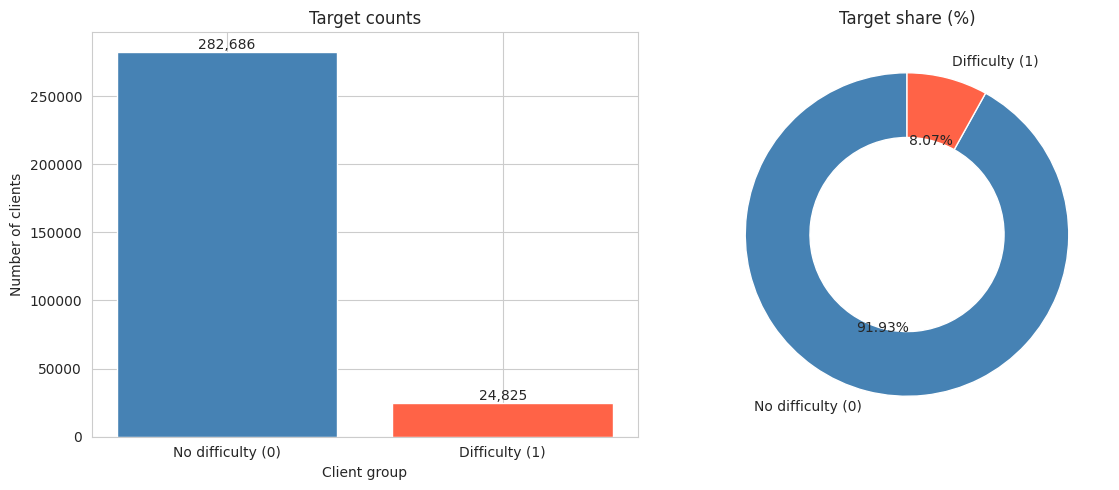

In [ ]:
## Imbalance charts

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
labels = ["No difficulty (0)", "Difficulty (1)"]
colors = ["steelblue", "tomato"]

# Bar chart: absolute counts
axes[0].bar(labels, target_counts.values, color=colors)
axes[0].set_title("Target counts")
axes[0].set_xlabel("Client group")
axes[0].set_ylabel("Number of clients")
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

# Donut chart: percentages
axes[1].pie(target_counts.values, labels=labels, colors=colors,
            autopct="%1.2f%%", startangle=90,
            wedgeprops={"width": 0.4})
axes[1].set_title("Target share (%)")

plt.tight_layout()
plt.show()

In [ ]:
## Why imbalance matters here

# A model that always predicts "no difficulty" would be right this often
baseline_acc = target_counts[0] / len(app_df) * 100
print(f"Accuracy of always predicting 0: {baseline_acc:.2f}%")

Accuracy of always predicting 0: 91.93%


# Phase 4: Univariate and segmented univariate analysis

In [ ]:
# Summary statistics for continuous columns

def summary_stats(df, cols):
    """Mean, median, mode, spread, and shape for each column."""
    rows = []
    for col in cols:
        s = df[col].dropna()
        mode_vals = s.mode()
        rows.append({
            "column": col,
            "count": len(s),
            "mean": s.mean(),
            "median": s.median(),
            "mode": mode_vals.iloc[0] if len(mode_vals) > 0 else np.nan,
            "std": s.std(),
            "variance": s.var(),
            "min": s.min(),
            "max": s.max(),
            "range": s.max() - s.min(),
            "iqr": s.quantile(0.75) - s.quantile(0.25),
            "skew": s.skew(),
        })
    return pd.DataFrame(rows).set_index("column")

stats_all = summary_stats(app_df, cont_cols)
stats_all.round(2)

,count,mean,median,mode,std,variance,min,max,range,iqr,skew
column,,,,,,,,,,,
AMT_INCOME_TOTAL,307511,168797.92,147150.00,135000.00,237123.15,5.622739e+10,25650.00,1.170000e+08,1.169744e+08,90000.00,391.56
AMT_CREDIT,307511,599026.00,513531.00,450000.00,402490.78,1.619988e+11,45000.00,4.050000e+06,4.005000e+06,538650.00,1.23
AMT_ANNUITY,307499,27108.57,24903.00,9000.00,14493.74,2.100684e+08,1615.50,2.580255e+05,2.564100e+05,18072.00,1.58
AMT_GOODS_PRICE,307233,538396.21,450000.00,450000.00,369446.46,1.364907e+11,40500.00,4.050000e+06,4.009500e+06,441000.00,1.35
REGION_POPULATION_RELATIVE,307511,0.02,0.02,0.04,0.01,0.000000e+00,0.00,7.000000e-02,7.000000e-02,0.02,1.49
OWN_CAR_AGE,101248,10.34,9.00,7.00,7.39,5.467000e+01,0.00,9.100000e+01,9.100000e+01,10.00,1.07
EXT_SOURCE_1,134133,0.50,0.51,0.36,0.21,4.000000e-02,0.01,9.600000e-01,9.500000e-01,0.34,-0.07
EXT_SOURCE_2,306851,0.51,0.57,0.29,0.19,4.000000e-02,0.00,8.500000e-01,8.500000e-01,0.27,-0.79
EXT_SOURCE_3,246546,0.51,0.54,0.75,0.19,4.000000e-02,0.00,9.000000e-01,9.000000e-01,0.30,-0.41


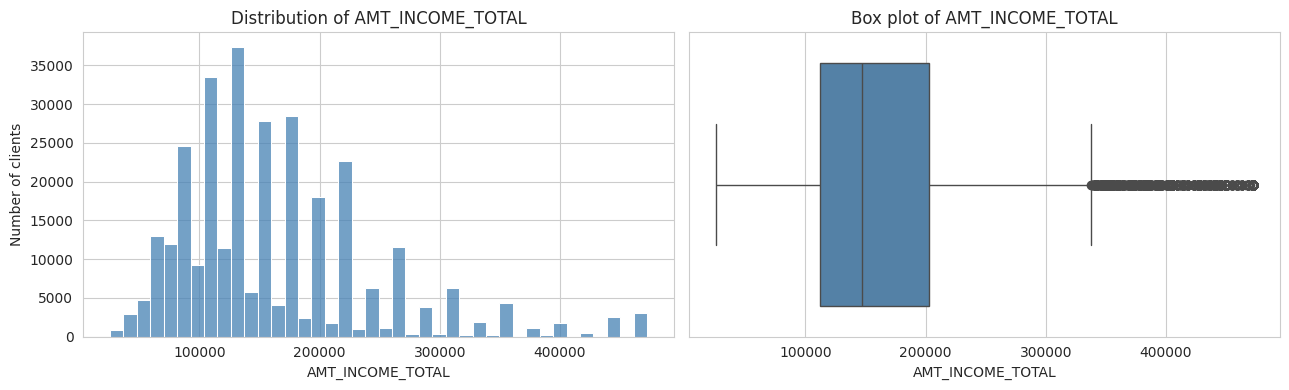

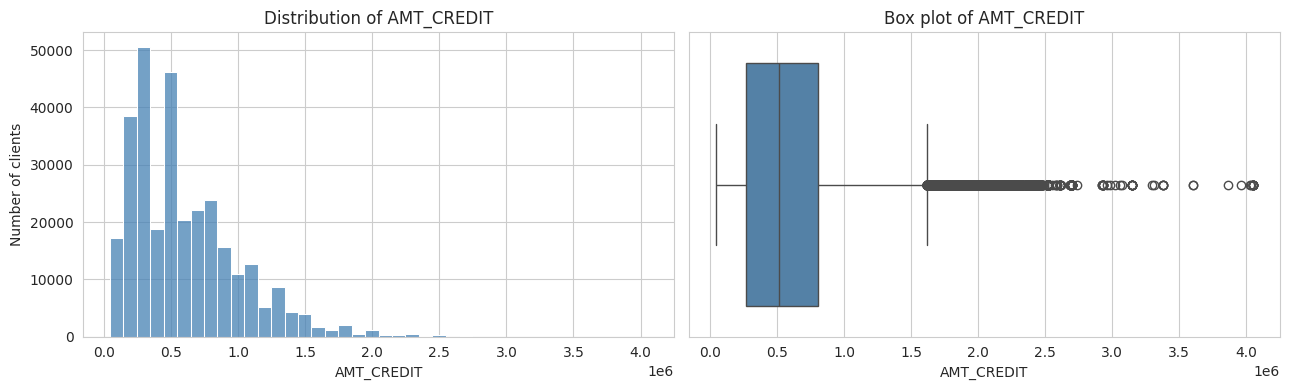

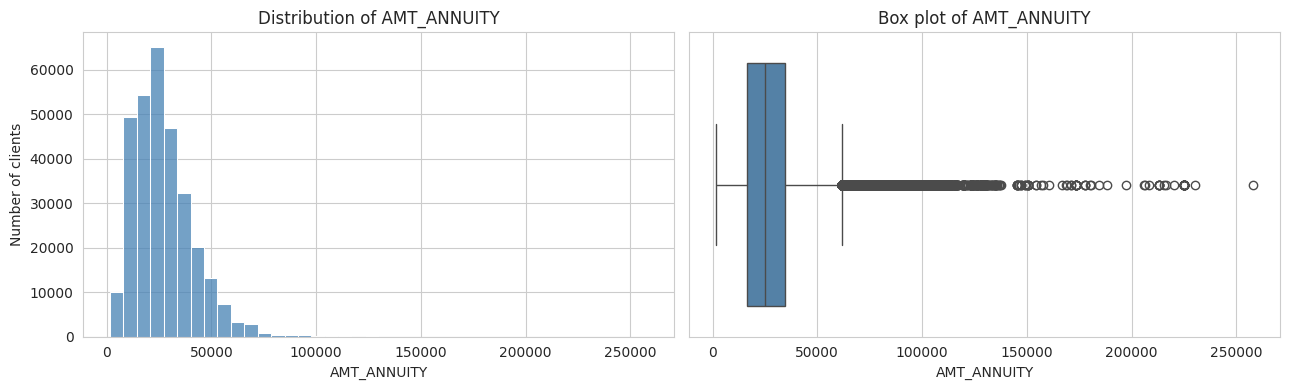

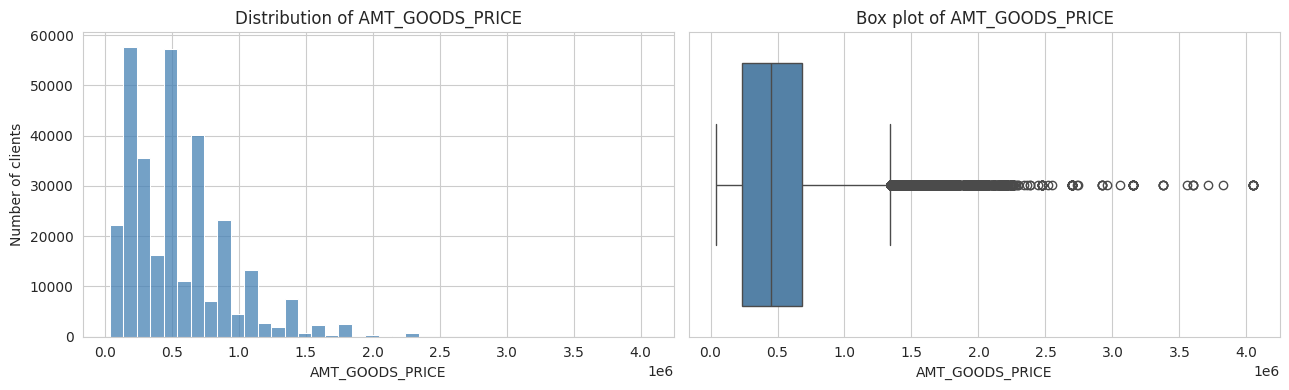

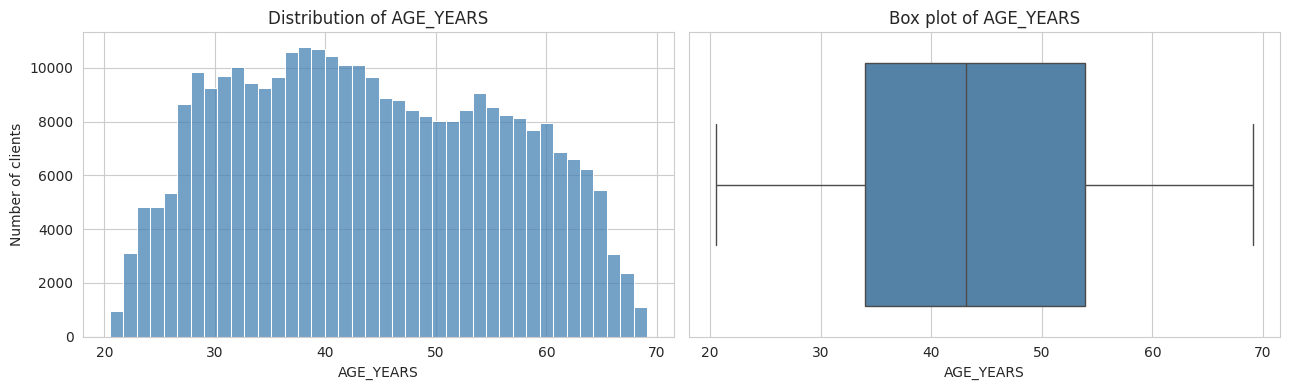

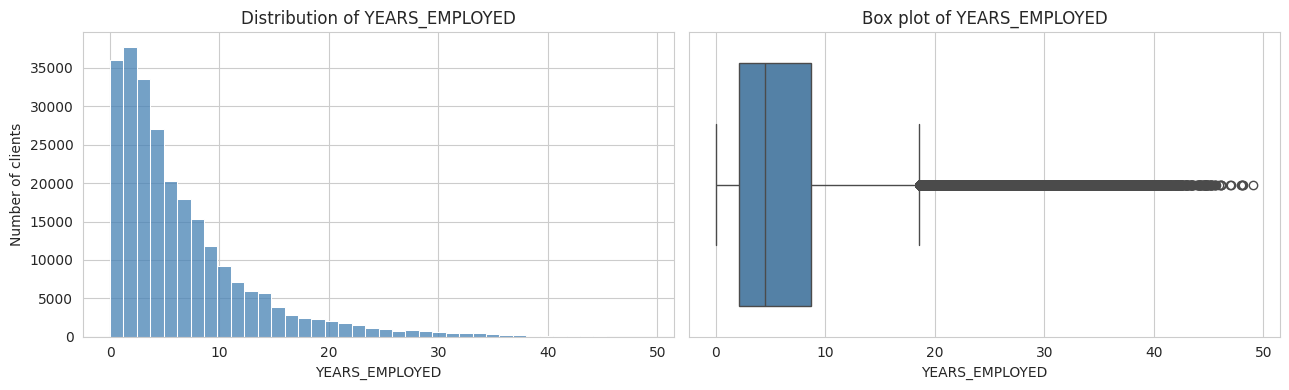

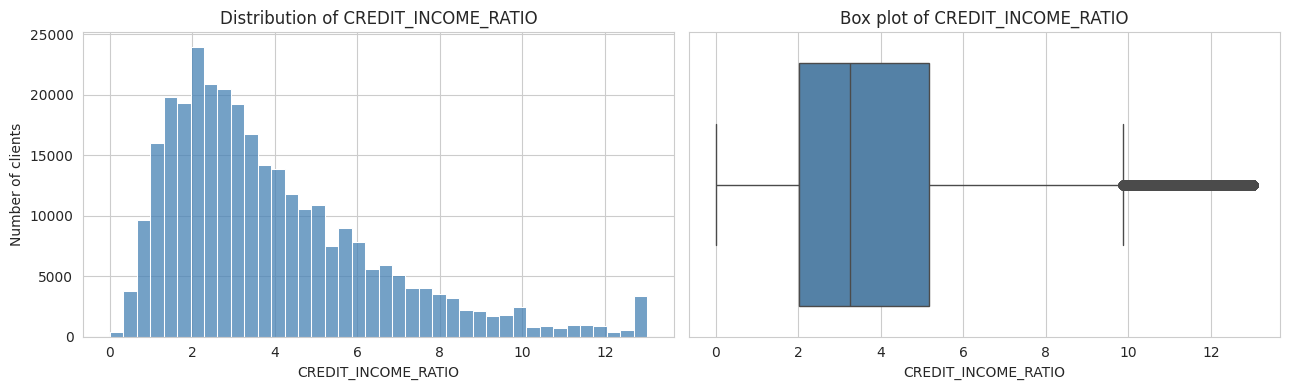

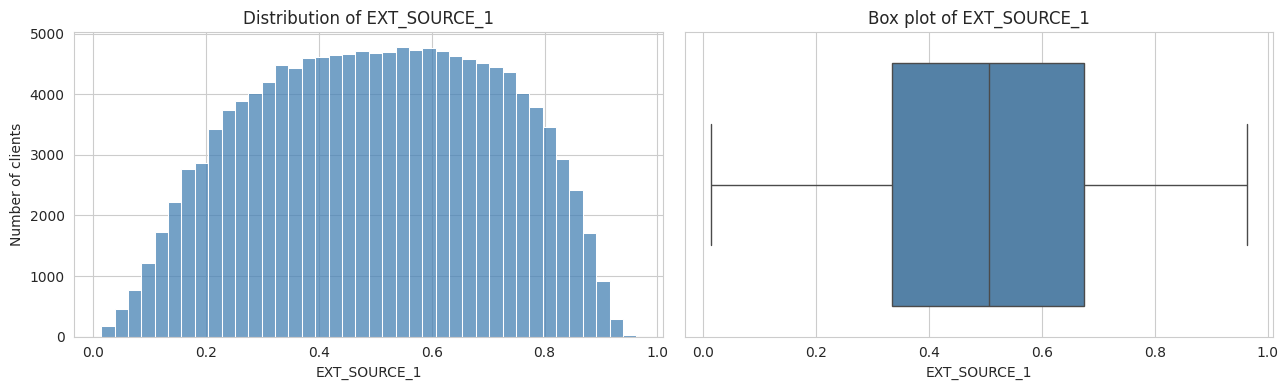

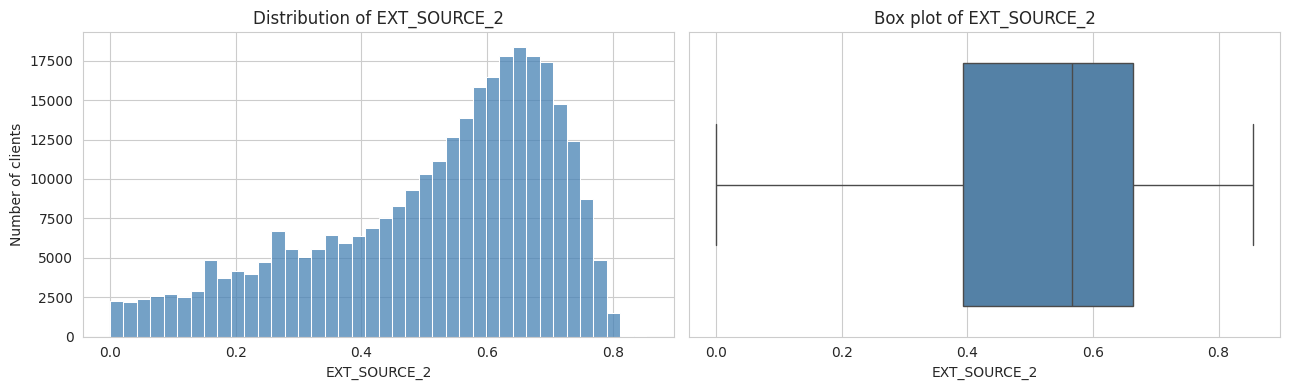

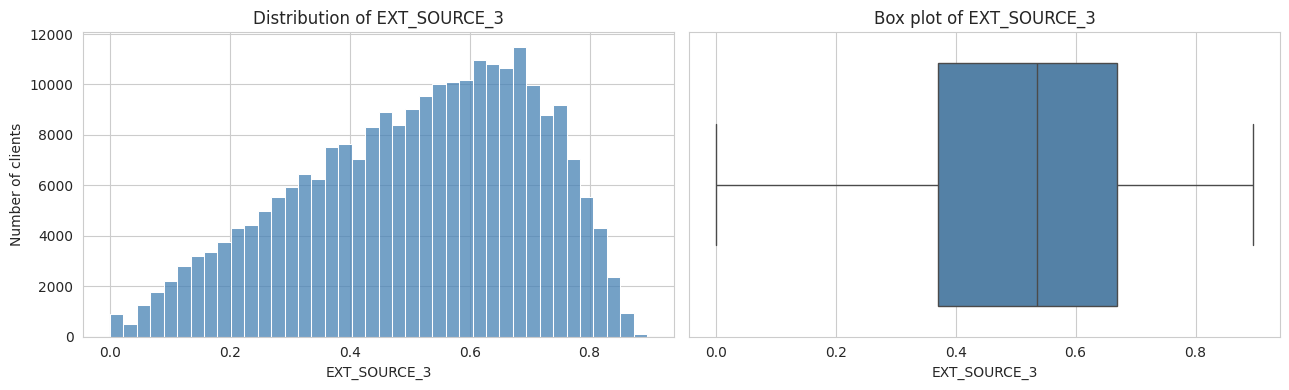

In [ ]:
## Histograms and box plots in a loop

# Money and ratio columns: histograms and box plots
plot_cols = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
             "AGE_YEARS", "YEARS_EMPLOYED", "CREDIT_INCOME_RATIO",
             "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]

for col in plot_cols:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    sns.histplot(app_clip[col].dropna(), bins=40, color="steelblue", ax=axes[0])
    axes[0].set_title(f"Distribution of {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Number of clients")

    sns.boxplot(x=app_clip[col], color="steelblue", ax=axes[1])
    axes[1].set_title(f"Box plot of {col}")
    axes[1].set_xlabel(col)

    plt.tight_layout()
    plt.show()

In [ ]:
## Categorical columns, counts and shares

# Categorical columns to explore (ORGANIZATION_TYPE has many levels, handled separately)
cat_plot_cols = ["NAME_CONTRACT_TYPE", "CODE_GENDER", "FLAG_OWN_CAR", "FLAG_OWN_REALTY",
                 "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS",
                 "NAME_HOUSING_TYPE", "OCCUPATION_TYPE", "AGE_GROUP",
                 "INCOME_GROUP", "CREDIT_GROUP"]

for col in cat_plot_cols:
    share = app_df[col].value_counts(normalize=True, dropna=False) * 100
    print(col)
    print(share.round(2))
    print()

NAME_CONTRACT_TYPE
NAME_CONTRACT_TYPE
Cash loans         90.48
Revolving loans     9.52
Name: proportion, dtype: float64

CODE_GENDER
CODE_GENDER
F      65.83
M      34.16
NaN     0.00
Name: proportion, dtype: float64

FLAG_OWN_CAR
FLAG_OWN_CAR
N    65.99
Y    34.01
Name: proportion, dtype: float64

FLAG_OWN_REALTY
FLAG_OWN_REALTY
Y    69.37
N    30.63
Name: proportion, dtype: float64

NAME_INCOME_TYPE
NAME_INCOME_TYPE
Working                 51.63
Commercial associate    23.29
Pensioner               18.00
State servant            7.06
Unemployed               0.01
Student                  0.01
Businessman              0.00
Maternity leave          0.00
Name: proportion, dtype: float64

NAME_EDUCATION_TYPE
NAME_EDUCATION_TYPE
Secondary / secondary special    71.02
Higher education                 24.34
Incomplete higher                 3.34
Lower secondary                   1.24
Academic degree                   0.05
Name: proportion, dtype: float64

NAME_FAMILY_STATUS
NAME_FAMILY_STA

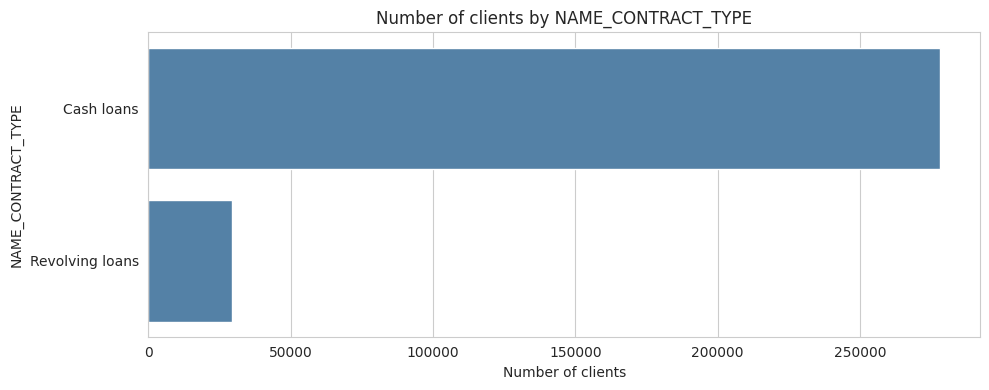

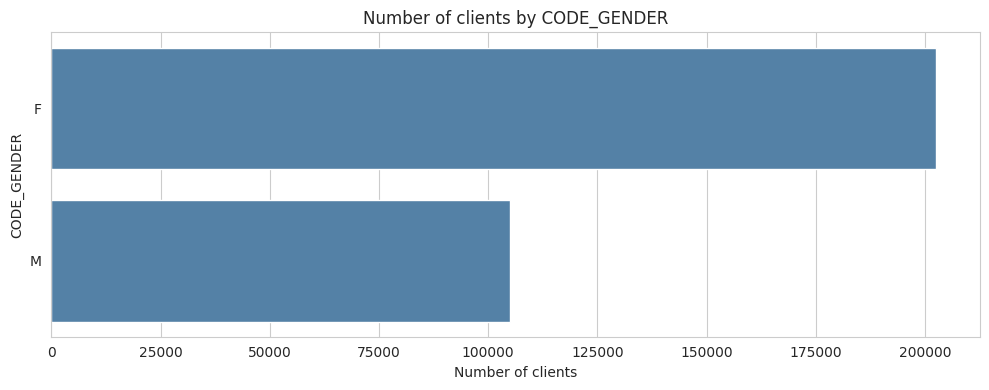

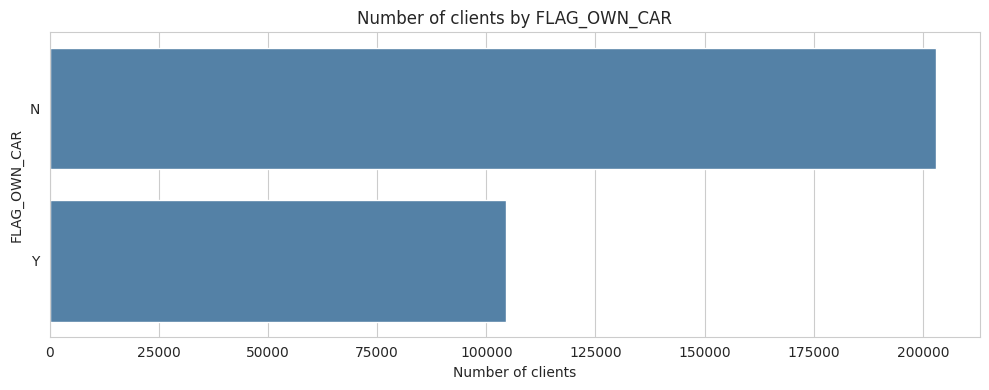

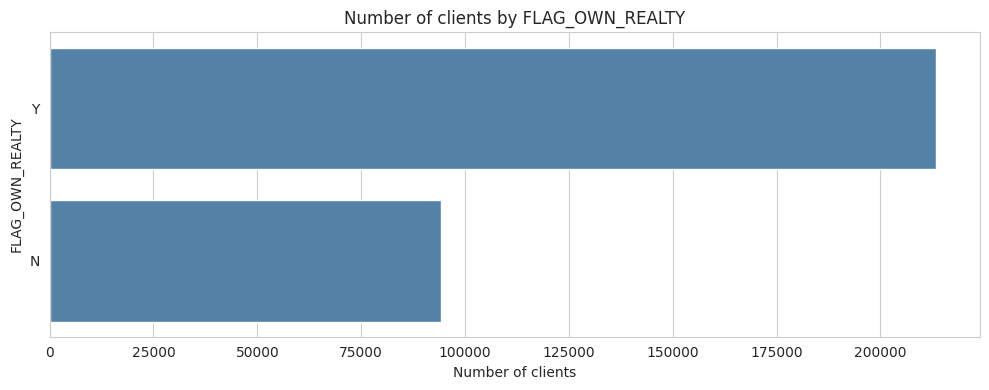

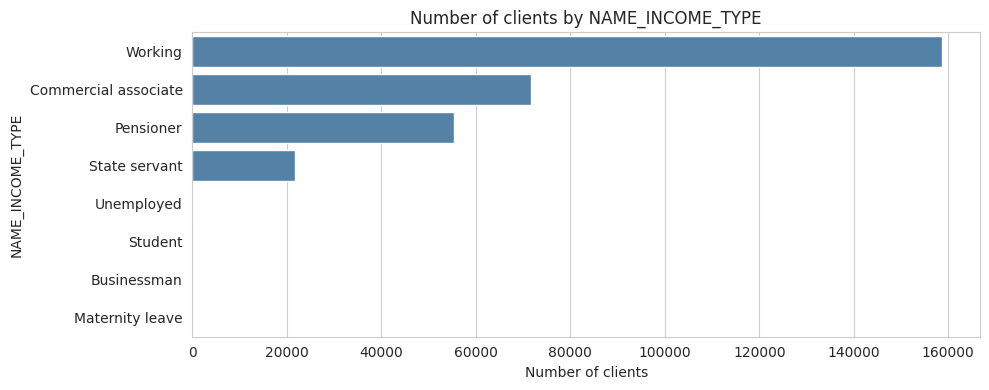

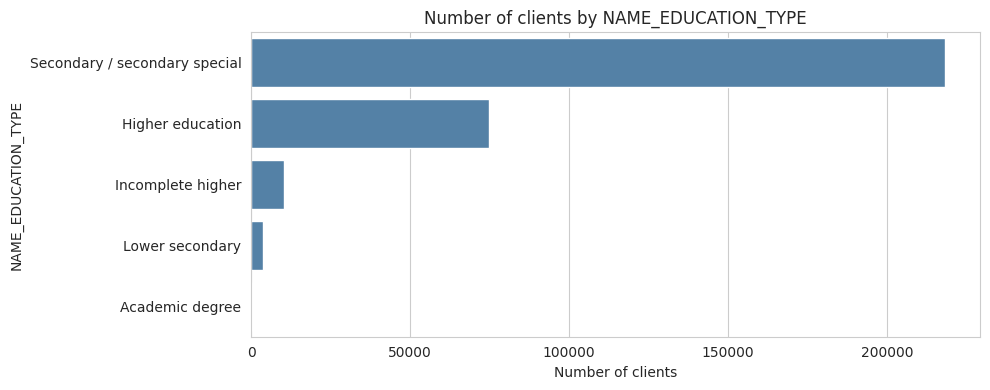

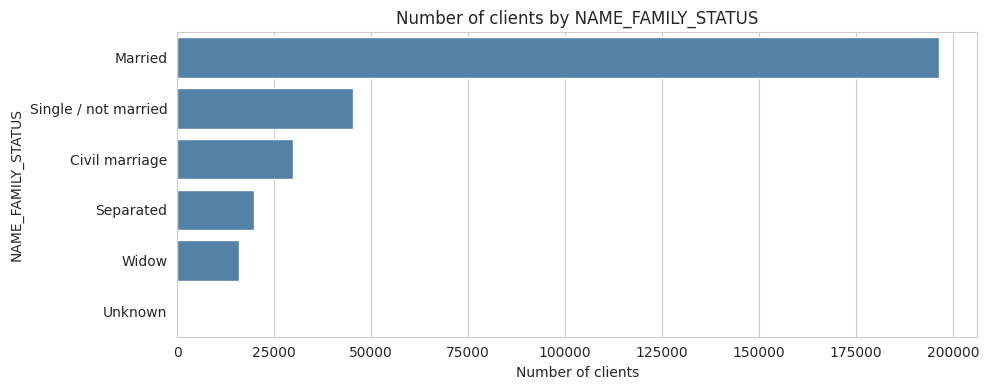

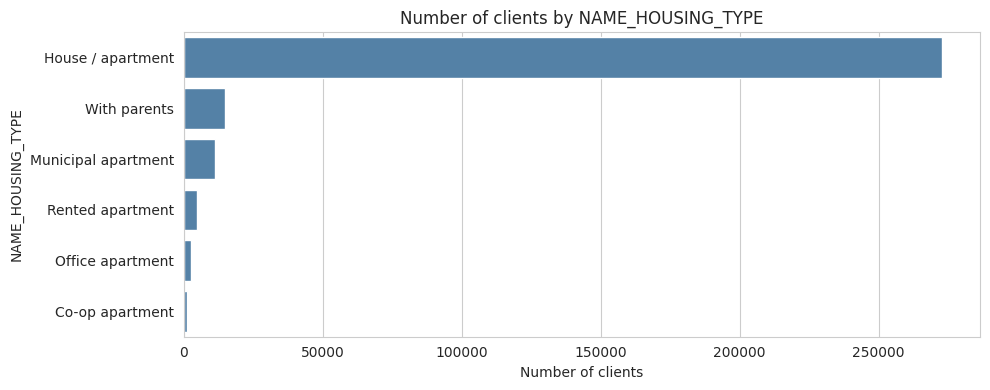

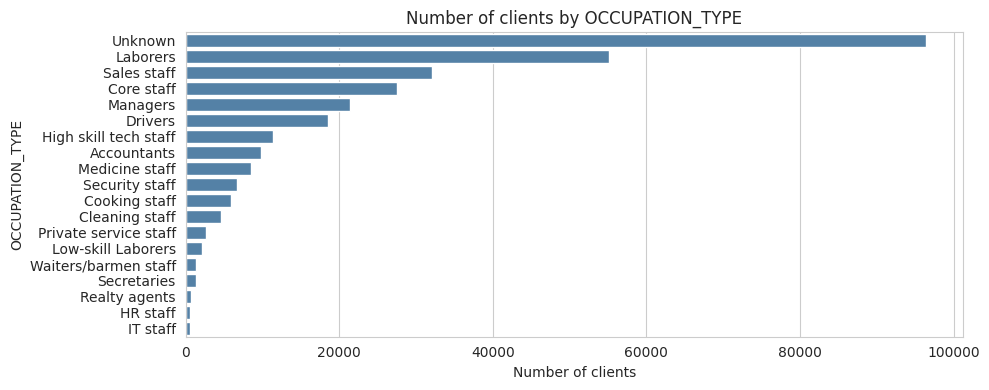

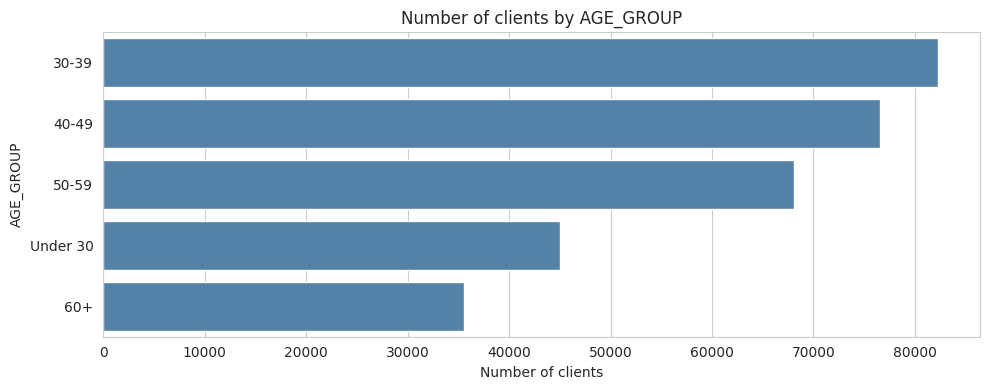

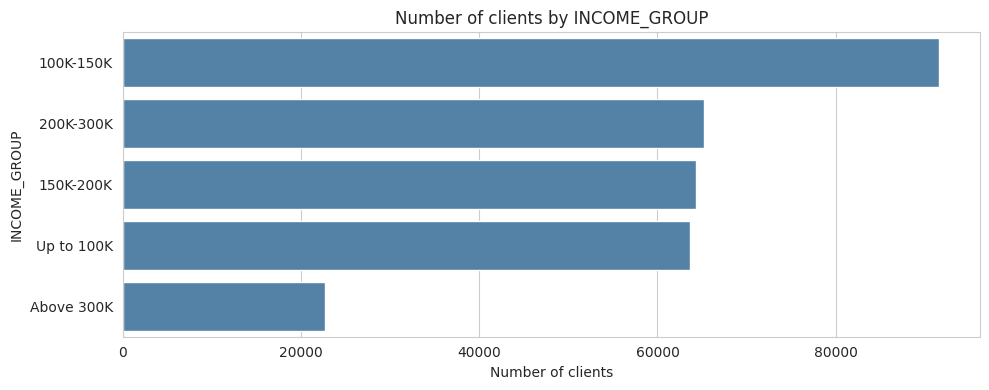

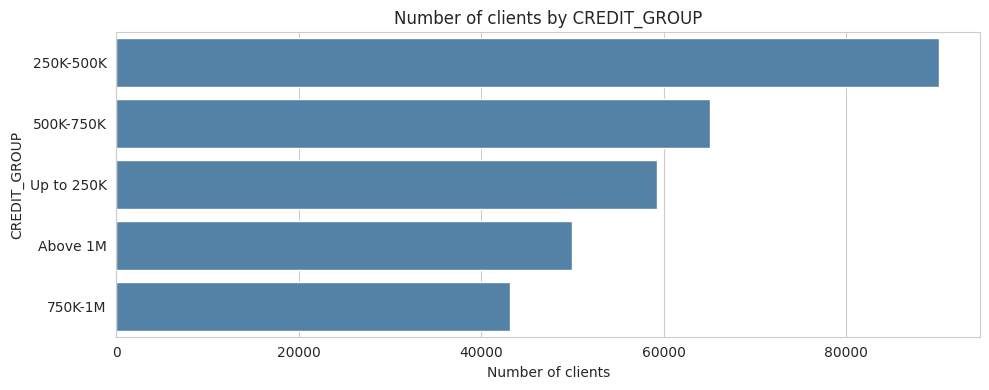

In [ ]:
# Categorical univariate plots in a loop

for col in cat_plot_cols:
    order = app_df[col].value_counts().index
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.countplot(data=app_df, y=col, order=order, color="steelblue", ax=ax)
    ax.set_title(f"Number of clients by {col}")
    ax.set_xlabel("Number of clients")
    ax.set_ylabel(col)
    plt.tight_layout()
    plt.show()

TARGET                        0           1
AMT_CREDIT           517788.000  497520.000
AMT_ANNUITY           24876.000   25263.000
AGE_YEARS                43.499      39.129
YEARS_EMPLOYED            4.633       3.370
CREDIT_INCOME_RATIO       3.267       3.253
EXT_SOURCE_1              0.517       0.362
EXT_SOURCE_2              0.574       0.440
EXT_SOURCE_3              0.546       0.379


/tmp/ipykernel_1416/163261862.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=app_clip, x="TARGET", y=col, palette=["steelblue", "tomato"], ax=ax)
/tmp/ipykernel_1416/163261862.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=app_clip, x="TARGET", y=col, palette=["steelblue", "tomato"], ax=ax)
/tmp/ipykernel_1416/163261862.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=app_clip, x="TARGET", y=col, palette=["steelblue", "tomato"], ax=ax)
/tmp/ipykernel_1416/163261862.py:12: FutureWarning: 

Passing `palette` with

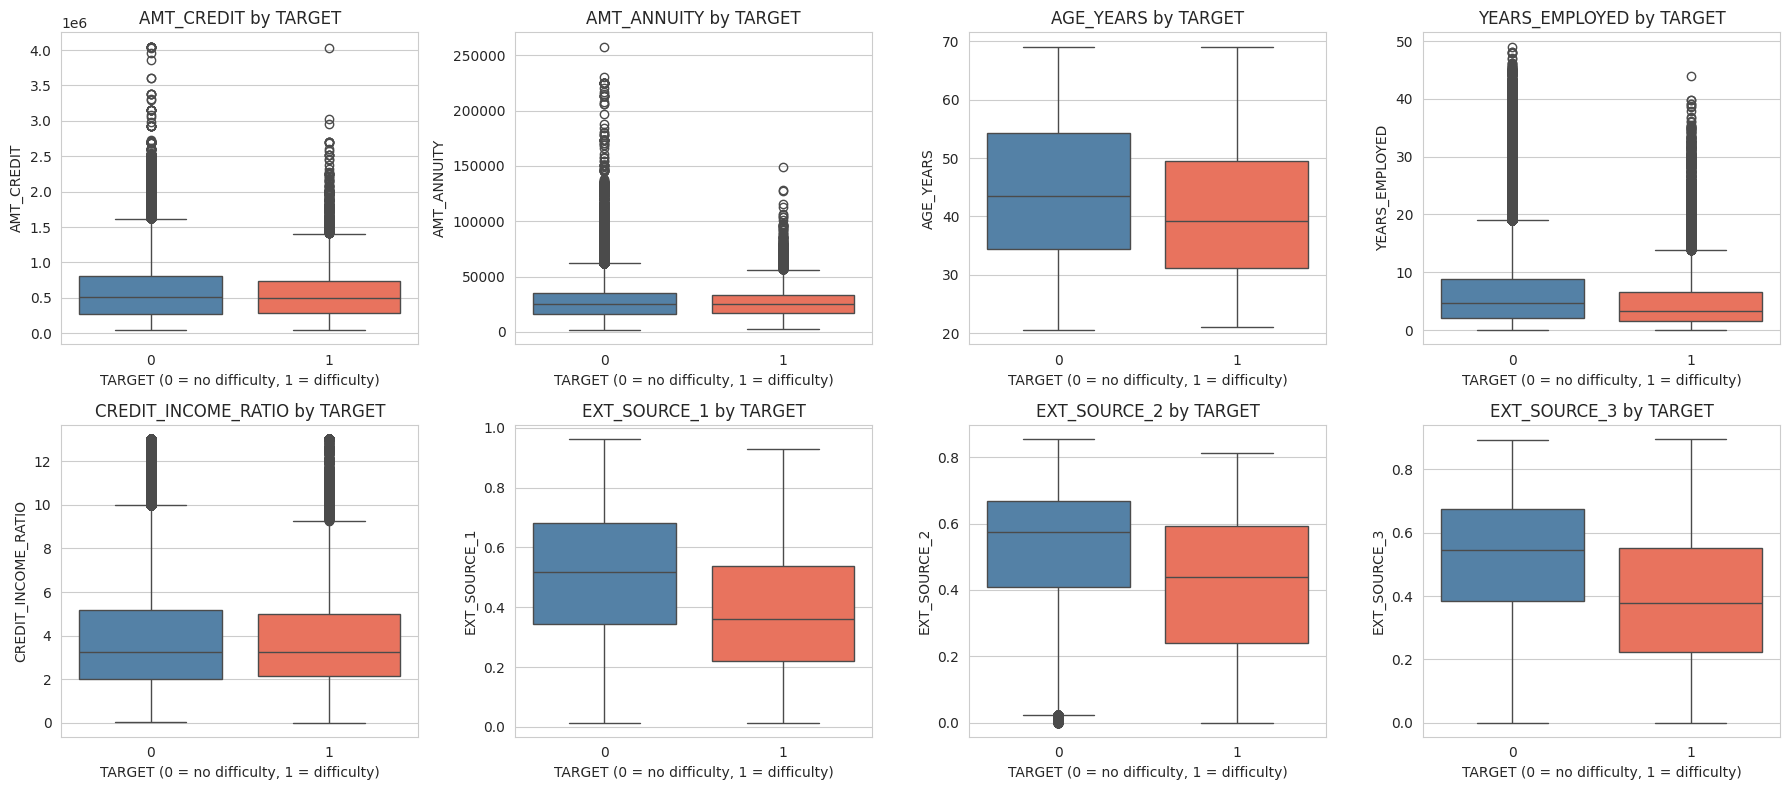

In [ ]:
## Numerical columns split by target

seg_cols = ["AMT_CREDIT", "AMT_ANNUITY", "AGE_YEARS", "YEARS_EMPLOYED",
            "CREDIT_INCOME_RATIO", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]

# Median by target (numbers first)
print(app_df.groupby("TARGET")[seg_cols].median().round(3).T)

# Box plots by target
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), seg_cols):
    sns.boxplot(data=app_clip, x="TARGET", y=col, palette=["steelblue", "tomato"], ax=ax)
    ax.set_title(f"{col} by TARGET")
    ax.set_xlabel("TARGET (0 = no difficulty, 1 = difficulty)")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

In [ ]:
# Default rate by category

overall_rate = app_df["TARGET"].mean() * 100

def default_rate_table(df, col, min_size=500):
    """Default rate and group size per category."""
    t = df.groupby(col, observed=True)["TARGET"].agg(["count", "mean"])
    t["default_rate"] = (t["mean"] * 100).round(2)
    t = t.rename(columns={"count": "n_clients"}).drop(columns="mean")
    t["small_group"] = t["n_clients"] < min_size
    return t.sort_values("default_rate", ascending=False)

for col in cat_plot_cols:
    t = default_rate_table(app_df, col)
    print(col)
    print(t)
    print()

NAME_CONTRACT_TYPE
                    n_clients  default_rate  small_group
NAME_CONTRACT_TYPE                                      
Cash loans             278232          8.35        False
Revolving loans         29279          5.48        False

CODE_GENDER
             n_clients  default_rate  small_group
CODE_GENDER                                      
M               105059         10.14        False
F               202448          7.00        False

FLAG_OWN_CAR
              n_clients  default_rate  small_group
FLAG_OWN_CAR                                      
N                202924          8.50        False
Y                104587          7.24        False

FLAG_OWN_REALTY
                 n_clients  default_rate  small_group
FLAG_OWN_REALTY                                      
N                    94199          8.32        False
Y                   213312          7.96        False

NAME_INCOME_TYPE
                      n_clients  default_rate  small_group
NAME_INCOME_

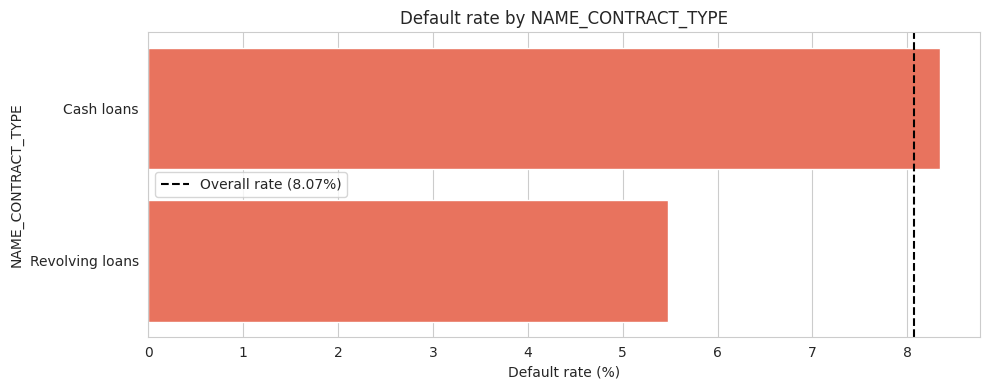

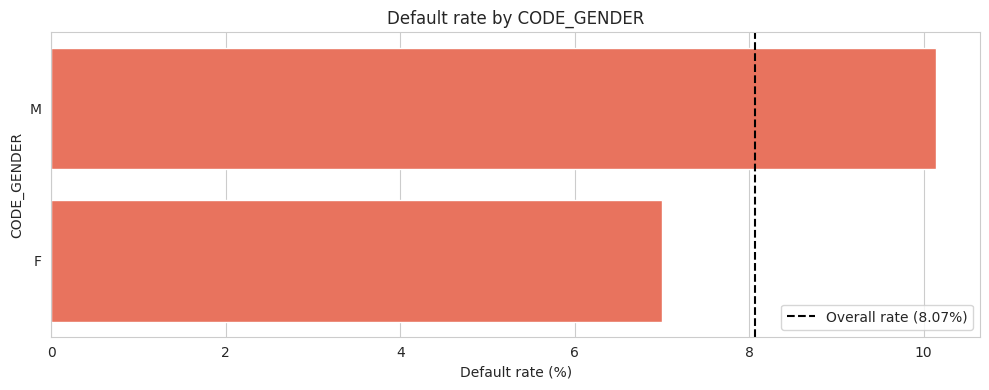

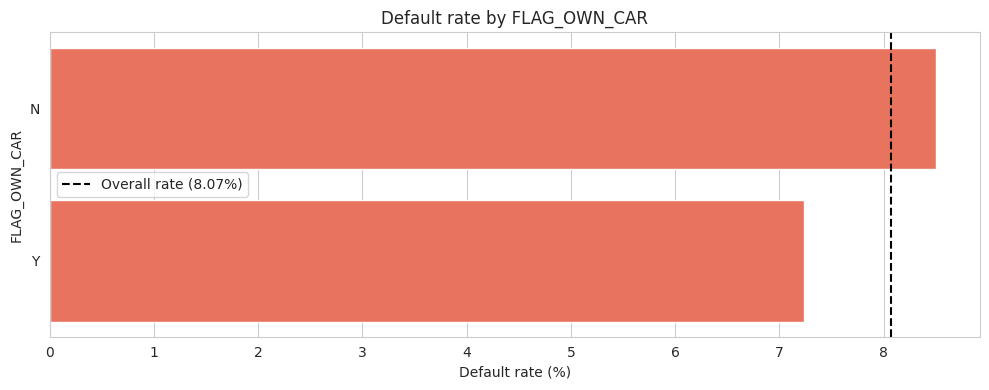

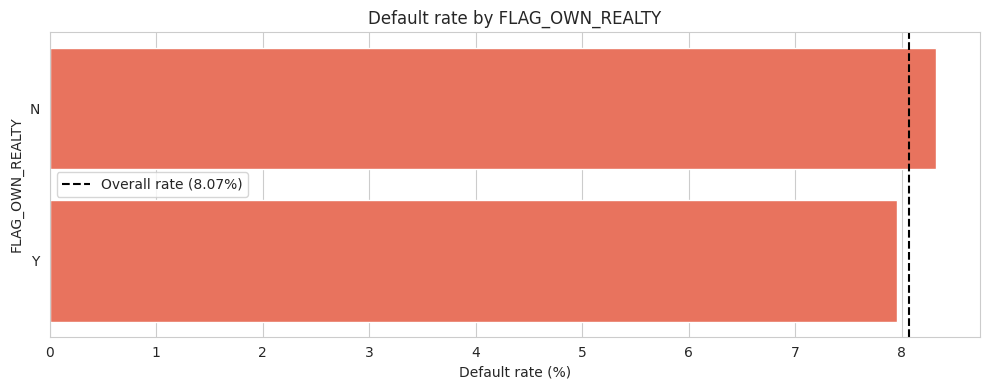

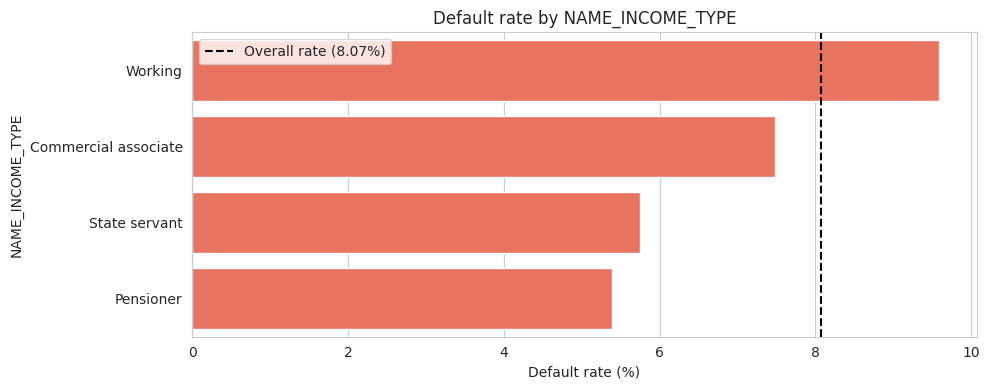

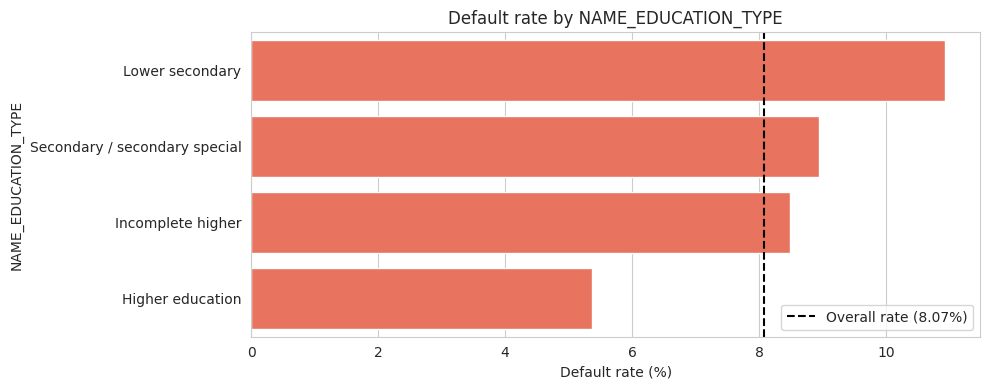

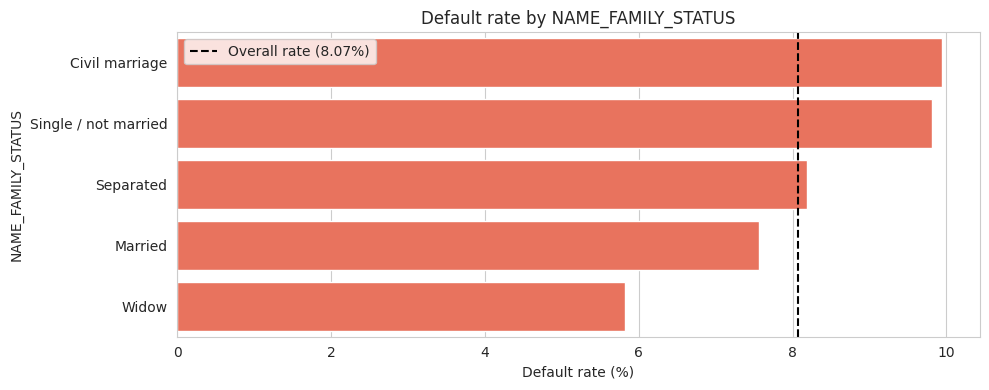

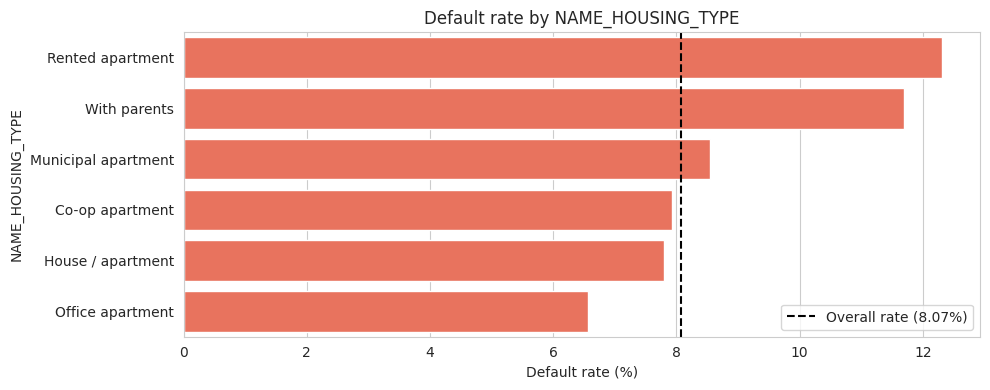

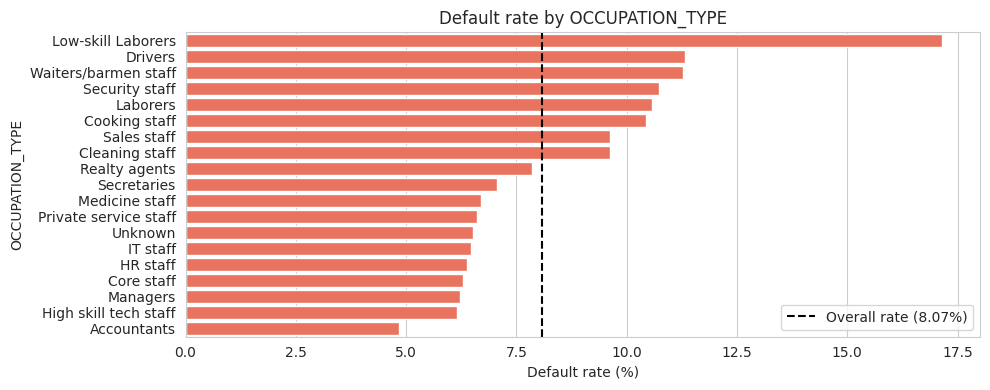

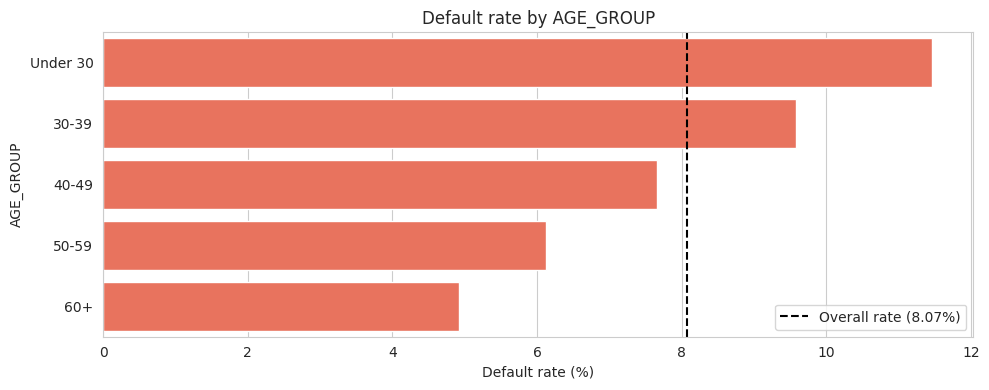

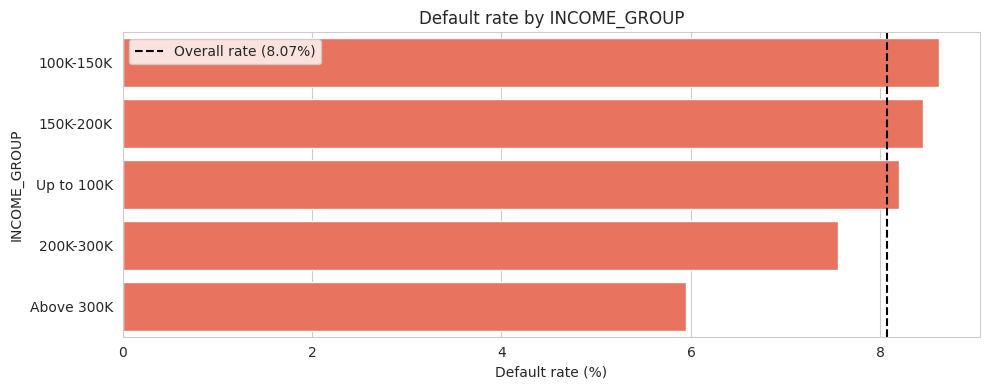

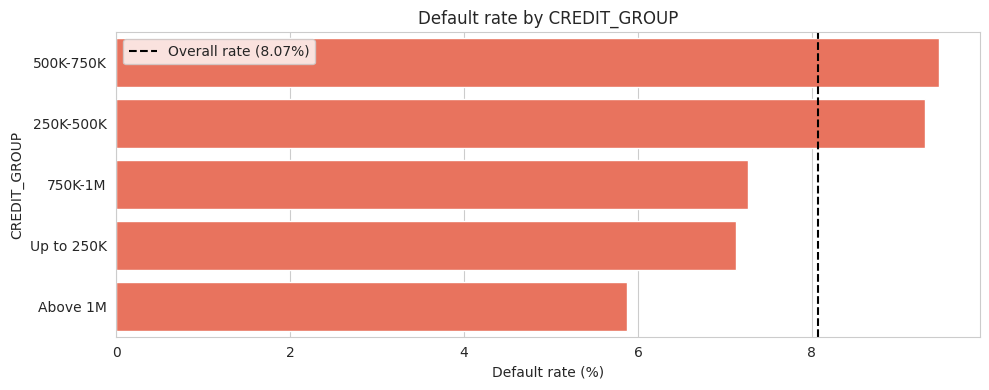

In [ ]:
# Default rate plots in a loop

for col in cat_plot_cols:
    t = default_rate_table(app_df, col)
    t = t[~t["small_group"]]          # hide tiny groups in the chart

    fig, ax = plt.subplots(figsize=(10, 4))
    sns.barplot(x=t["default_rate"], y=t.index.astype(str), color="tomato", ax=ax)
    ax.axvline(overall_rate, color="black", linestyle="--", label=f"Overall rate ({overall_rate:.2f}%)")
    ax.set_title(f"Default rate by {col}")
    ax.set_xlabel("Default rate (%)")
    ax.set_ylabel(col)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
# Organization type (many levels)

t = default_rate_table(app_df, "ORGANIZATION_TYPE")
top_risky = t[~t["small_group"]].head(10)
top_safe = t[~t["small_group"]].tail(10)

print("Highest default rates:")
print(top_risky)
print()
print("Lowest default rates:")
print(top_safe)

Highest default rates:
                   n_clients  default_rate  small_group
ORGANIZATION_TYPE                                      
Transport: type 3       1187         15.75        False
Restaurant              1811         11.71        False
Construction            6721         11.68        False
Industry: type 1        1039         11.07        False
Industry: type 3        3278         10.62        False
Agriculture             2454         10.47        False
Trade: type 3           3492         10.34        False
Self-employed          38412         10.17        False
Industry: type 4         877         10.15        False
Security                3247          9.98        False

Lowest default rates:
                     n_clients  default_rate  small_group
ORGANIZATION_TYPE                                        
Hotel                      966          6.42        False
School                    8893          5.91        False
Insurance                  597          5.70      

# Close Phase 4

In [ ]:
# Spread table in code

rows = []
for col in cat_plot_cols + ["ORGANIZATION_TYPE"]:
    t = default_rate_table(app_df, col)
    t = t[~t["small_group"]]               # ignore groups under 500 clients
    rows.append({
        "column": col,
        "groups_used": len(t),
        "highest": t["default_rate"].idxmax(),
        "highest_rate": t["default_rate"].max(),
        "lowest": t["default_rate"].idxmin(),
        "lowest_rate": t["default_rate"].min(),
        "spread_points": round(t["default_rate"].max() - t["default_rate"].min(), 2),
    })

spread_table = pd.DataFrame(rows).sort_values("spread_points", ascending=False)
spread_table

,column,groups_used,highest,highest_rate,lowest,lowest_rate,spread_points
8,OCCUPATION_TYPE,19,Low-skill Laborers,17.15,Accountants,4.83,12.32
12,ORGANIZATION_TYPE,41,Transport: type 3,15.75,Trade: type 6,4.60,11.15
9,AGE_GROUP,5,Under 30,11.46,60+,4.92,6.54
7,NAME_HOUSING_TYPE,6,Rented apartment,12.31,Office apartment,6.57,5.74
5,NAME_EDUCATION_TYPE,4,Lower secondary,10.93,Higher education,5.36,5.57
4,NAME_INCOME_TYPE,4,Working,9.59,Pensioner,5.39,4.20
6,NAME_FAMILY_STATUS,5,Civil marriage,9.94,Widow,5.82,4.12
11,CREDIT_GROUP,5,500K-750K,9.46,Above 1M,5.87,3.59
1,CODE_GENDER,2,M,10.14,F,7.00,3.14
0,NAME_CONTRACT_TYPE,2,Cash loans,8.35,Revolving loans,5.48,2.87


In [ ]:
# Rank numeric columns by separation

rows = []
for col in cont_cols:
    s0 = app_df.loc[app_df["TARGET"] == 0, col].dropna()
    s1 = app_df.loc[app_df["TARGET"] == 1, col].dropna()
    iqr = app_df[col].quantile(0.75) - app_df[col].quantile(0.25)
    gap = s1.median() - s0.median()
    rows.append({
        "column": col,
        "median_0": s0.median(),
        "median_1": s1.median(),
        "gap": gap,
        "gap_in_iqr": gap / iqr if iqr > 0 else np.nan,
    })

separation = pd.DataFrame(rows)
separation["abs_gap_in_iqr"] = separation["gap_in_iqr"].abs()
separation.sort_values("abs_gap_in_iqr", ascending=False).round(3)

,column,median_0,median_1,gap,gap_in_iqr,abs_gap_in_iqr
8,EXT_SOURCE_3,0.546,0.379,-0.167,-0.559,0.559
7,EXT_SOURCE_2,0.574,0.440,-0.134,-0.492,0.492
6,EXT_SOURCE_1,0.517,0.362,-0.156,-0.457,0.457
12,AMT_REQ_CREDIT_BUREAU_YEAR,1.000,2.000,1.000,0.333,0.333
13,AGE_YEARS,43.499,39.129,-4.370,-0.219,0.219
5,OWN_CAR_AGE,9.000,11.000,2.000,0.200,0.200
16,YEARS_ID_PUBLISH,9.027,7.663,-1.364,-0.193,0.193
14,YEARS_EMPLOYED,4.633,3.370,-1.263,-0.191,0.191
0,AMT_INCOME_TOTAL,148500.000,135000.000,-13500.000,-0.150,0.150
17,YEARS_LAST_PHONE_CHANGE,2.126,1.627,-0.499,-0.140,0.140


# Phase 5: Bivariate and multivariate analysis

In [ ]:
## Default rate by credit to income band

# qcut makes 5 bands with about the same number of clients in each
ratio_group = pd.qcut(app_df["CREDIT_INCOME_RATIO"], 5)

t = app_df.groupby(ratio_group, observed=True)["TARGET"].agg(["count", "mean"])
t["default_rate"] = (t["mean"] * 100).round(2)
t = t.rename(columns={"count": "n_clients"}).drop(columns="mean")
t

,n_clients,default_rate
CREDIT_INCOME_RATIO,,
"(0.00381, 1.818]",61539,7.34
"(1.818, 2.764]",61502,8.57
"(2.764, 3.906]",61466,8.93
"(3.906, 5.769]",61505,8.28
"(5.769, 84.737]",61499,7.25


In [ ]:
## Does age matter without pensioners?

is_pensioner = app_df["NAME_INCOME_TYPE"] == "Pensioner"

# Client counts first, so we can judge how stable each rate is
print(pd.crosstab(app_df["AGE_GROUP"], is_pensioner, colnames=["Pensioner"]))
print()

# Default rate (%) by age group, split by pensioner or not
rates = app_df.groupby(["AGE_GROUP", is_pensioner], observed=True)["TARGET"].mean().unstack() * 100
rates.columns = ["Not pensioner", "Pensioner"]
rates.round(2)

Pensioner  False  True 
AGE_GROUP              
Under 30   44868    132
30-39      81801    498
40-49      74728   1815
50-59      44742  23332
60+         6010  29585



,Not pensioner,Pensioner
AGE_GROUP,,
Under 30,11.45,13.64
30-39,9.57,11.45
40-49,7.63,8.54
50-59,6.49,5.43
60+,4.46,5.02


CREDIT_GROUP  Up to 250K  250K-500K  500K-750K  750K-1M  Above 1M
INCOME_GROUP                                                     
Up to 100K         24669      21085      10417     4989      2538
100K-150K          19483      31439      19567    11826      9276
150K-200K           8555      18974      15187    10321     11270
200K-300K           5488      15121      15542    11630     17395
Above 300K          1003       3516       4381     4333      9506


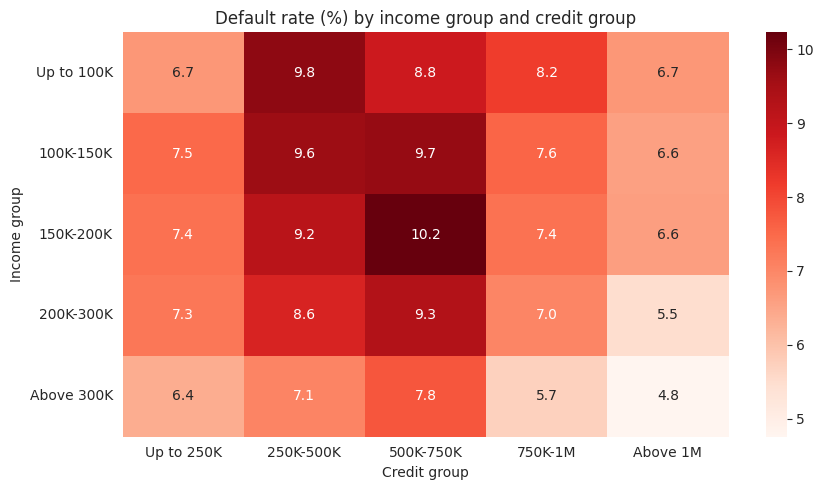

In [ ]:
## Income and credit together

rate = app_df.pivot_table(index="INCOME_GROUP", columns="CREDIT_GROUP",
                          values="TARGET", aggfunc="mean", observed=True) * 100
size = app_df.pivot_table(index="INCOME_GROUP", columns="CREDIT_GROUP",
                          values="TARGET", aggfunc="count", observed=True)
print(size)

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(rate, annot=True, fmt=".1f", cmap="Reds", ax=ax)
ax.set_title("Default rate (%) by income group and credit group")
ax.set_xlabel("Credit group")
ax.set_ylabel("Income group")
plt.tight_layout()
plt.show()

Correlation: 0.987


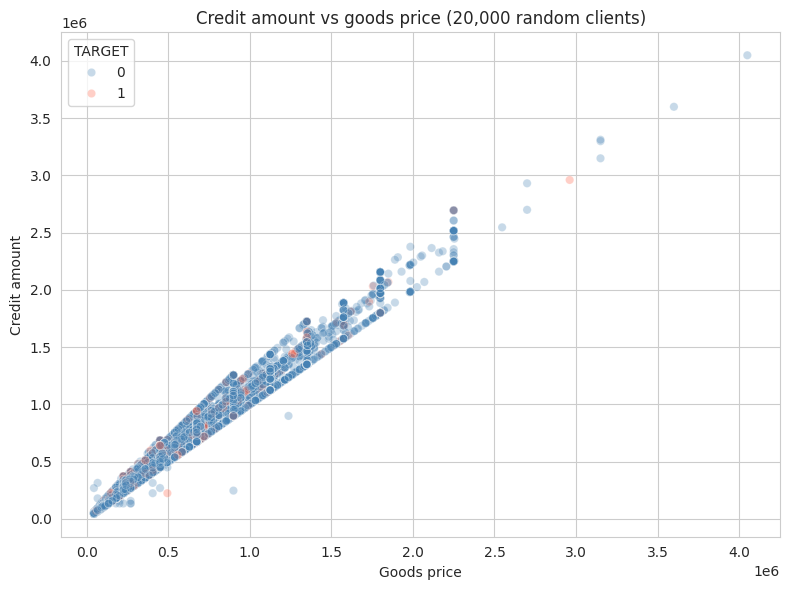

In [ ]:
## Credit vs goods price

print("Correlation:", round(app_df[["AMT_CREDIT", "AMT_GOODS_PRICE"]].corr().iloc[0, 1], 3))

# 307,511 points would overlap, so we plot a random sample
sample = app_clip.sample(20000, random_state=42)

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=sample, x="AMT_GOODS_PRICE", y="AMT_CREDIT", hue="TARGET",
                palette=["steelblue", "tomato"], alpha=0.3, ax=ax)
ax.set_title("Credit amount vs goods price (20,000 random clients)")
ax.set_xlabel("Goods price")
ax.set_ylabel("Credit amount")
plt.tight_layout()
plt.show()

# Close Phase 5

In [ ]:
## Heatmap rates and dictionary text

# Rate table behind the Cell 67 heatmap
print(rate.round(2))
print()

# Lowest and highest credit group inside each income group
for inc in rate.index:
    row = rate.loc[inc]
    print(f"{inc}: lowest {row.idxmin()} ({row.min():.2f}%), highest {row.idxmax()} ({row.max():.2f}%)")
print()

# What these columns mean (the DAYS columns became YEARS columns in Cell 37)
desc[desc["Row"].isin(["DAYS_ID_PUBLISH", "DAYS_LAST_PHONE_CHANGE",
                       "AMT_REQ_CREDIT_BUREAU_YEAR", "OBS_30_CNT_SOCIAL_CIRCLE"])][["Row", "Description"]]

CREDIT_GROUP  Up to 250K  250K-500K  500K-750K  750K-1M  Above 1M
INCOME_GROUP                                                     
Up to 100K          6.74       9.79       8.82     8.18      6.74
100K-150K           7.51       9.62       9.71     7.58      6.58
150K-200K           7.38       9.18      10.23     7.36      6.61
200K-300K           7.27       8.64       9.30     7.02      5.48
Above 300K          6.38       7.05       7.78     5.72      4.75

Up to 100K: lowest Above 1M (6.74%), highest 250K-500K (9.79%)
100K-150K: lowest Above 1M (6.58%), highest 500K-750K (9.71%)
150K-200K: lowest Above 1M (6.61%), highest 500K-750K (10.23%)
200K-300K: lowest Above 1M (5.48%), highest 500K-750K (9.30%)
Above 300K: lowest Above 1M (4.75%), highest 500K-750K (7.78%)



,Row,Description
20,DAYS_ID_PUBLISH,How many days before the application did client change the identity document with which he applied for the loan
91,OBS_30_CNT_SOCIAL_CIRCLE,How many observation of client's social surroundings with observable 30 DPD (days past due) default
95,DAYS_LAST_PHONE_CHANGE,How many days before application did client change phone
121,AMT_REQ_CREDIT_BUREAU_YEAR,Number of enquiries to Credit Bureau about the client one day year (excluding last 3 months before application)


In [ ]:
## Why is the top ratio band low?

ratio_group = pd.qcut(app_df["CREDIT_INCOME_RATIO"], 5)    # same bands as Cell 65
is_pensioner = app_df["NAME_INCOME_TYPE"] == "Pensioner"

for name, other in [("Contract type", app_df["NAME_CONTRACT_TYPE"]),
                    ("Pensioner", is_pensioner)]:
    g = app_df.groupby([ratio_group, other], observed=True)["TARGET"]
    print(name, "- number of clients")
    print(g.count().unstack())
    print(name, "- default rate (%)")
    print((g.mean().unstack() * 100).round(2))
    print()

Contract type - number of clients
NAME_CONTRACT_TYPE   Cash loans  Revolving loans
CREDIT_INCOME_RATIO                             
(0.00381, 1.818]          49576            11963
(1.818, 2.764]            51717             9785
(2.764, 3.906]            55035             6431
(3.906, 5.769]            60667              838
(5.769, 84.737]           61237              262
Contract type - default rate (%)
NAME_CONTRACT_TYPE   Cash loans  Revolving loans
CREDIT_INCOME_RATIO                             
(0.00381, 1.818]           7.64             6.09
(1.818, 2.764]             9.09             5.79
(2.764, 3.906]             9.48             4.20
(3.906, 5.769]             8.34             4.06
(5.769, 84.737]            7.28             1.91

Pensioner - number of clients
NAME_INCOME_TYPE     False  True 
CREDIT_INCOME_RATIO              
(0.00381, 1.818]     52416   9123
(1.818, 2.764]       51212  10290
(2.764, 3.906]       50633  10833
(3.906, 5.769]       50124  11381
(5.769, 84.7

# Phase 6: Correlation by target segment

In [ ]:
## Column list and the outlier check

corr_cols = [c for c in cont_cols if c != "CREDIT_INCOME_RATIO"]
print(len(corr_cols), "columns. TARGET in list:", "TARGET" in corr_cols)
print()

# One income value (117M) belongs to a defaulter. Compare the same pair on both copies.
raw1 = app_df[app_df["TARGET"] == 1]
clip1 = app_clip[app_clip["TARGET"] == 1]
print("AMT_INCOME_TOTAL vs AMT_CREDIT, TARGET = 1")
print("  app_df:  ", round(raw1["AMT_INCOME_TOTAL"].corr(raw1["AMT_CREDIT"]), 3))
print("  app_clip:", round(clip1["AMT_INCOME_TOTAL"].corr(clip1["AMT_CREDIT"]), 3))

18 columns. TARGET in list: False

AMT_INCOME_TOTAL vs AMT_CREDIT, TARGET = 1
  app_df:   0.038
  app_clip: 0.352


In [ ]:
## Top 10 pairs per segment

def top_pairs(corr, n=10):
    """Strongest pairs by absolute correlation. Each pair appears once."""
    mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)   # keep the upper triangle only
    pairs = corr.where(mask).stack().reset_index()
    pairs.columns = ["var_1", "var_2", "corr"]
    pairs["abs_corr"] = pairs["corr"].abs()
    return pairs.sort_values("abs_corr", ascending=False).head(n).reset_index(drop=True)

corr0 = app_clip.loc[app_clip["TARGET"] == 0, corr_cols].corr()
corr1 = app_clip.loc[app_clip["TARGET"] == 1, corr_cols].corr()

top0 = top_pairs(corr0)
top1 = top_pairs(corr1)

print("TARGET = 0 (no difficulty), clients:", (app_clip["TARGET"] == 0).sum())
print(top0.round(3))
print()
print("TARGET = 1 (difficulty), clients:", (app_clip["TARGET"] == 1).sum())
print(top1.round(3))

TARGET = 0 (no difficulty), clients: 282686
                      var_1                     var_2   corr  abs_corr
0  OBS_30_CNT_SOCIAL_CIRCLE  OBS_60_CNT_SOCIAL_CIRCLE  0.998     0.998
1                AMT_CREDIT           AMT_GOODS_PRICE  0.987     0.987
2               AMT_ANNUITY           AMT_GOODS_PRICE  0.777     0.777
3                AMT_CREDIT               AMT_ANNUITY  0.771     0.771
4              EXT_SOURCE_1                 AGE_YEARS  0.601     0.601
5          AMT_INCOME_TOTAL               AMT_ANNUITY  0.488     0.488
6          AMT_INCOME_TOTAL           AMT_GOODS_PRICE  0.419     0.419
7          AMT_INCOME_TOTAL                AMT_CREDIT  0.413     0.413
8                 AGE_YEARS            YEARS_EMPLOYED  0.353     0.353
9                 AGE_YEARS          YEARS_REGISTERED  0.333     0.333

TARGET = 1 (difficulty), clients: 24825
                      var_1                     var_2   corr  abs_corr
0  OBS_30_CNT_SOCIAL_CIRCLE  OBS_60_CNT_SOCIAL_CIRCLE  0.998   

In [ ]:
## Compare the two segments

# Overlap of the two top 10 lists
set0 = set(zip(top0["var_1"], top0["var_2"]))
set1 = set(zip(top1["var_1"], top1["var_2"]))
print("Pairs in both top 10 lists:", len(set0 & set1))
print("Only in TARGET = 0:", sorted(set0 - set1))
print("Only in TARGET = 1:", sorted(set1 - set0))
print()

# Pairs whose strength differs most between segments (all pairs, not only the top 10)
all0 = top_pairs(corr0, n=10000).set_index(["var_1", "var_2"])["corr"]
all1 = top_pairs(corr1, n=10000).set_index(["var_1", "var_2"])["corr"]
compare = pd.DataFrame({"corr_0": all0, "corr_1": all1})
compare["diff"] = compare["corr_1"] - compare["corr_0"]
compare["abs_diff"] = compare["diff"].abs()
compare.sort_values("abs_diff", ascending=False).head(10).round(3)

Pairs in both top 10 lists: 10
Only in TARGET = 0: []
Only in TARGET = 1: []



corr_0  corr_1   diff  abs_diff
var_1            var_2                                                      
AMT_GOODS_PRICE  AGE_YEARS                    0.045   0.136  0.091     0.091
AMT_CREDIT       AGE_YEARS                    0.047   0.135  0.088     0.088
AMT_INCOME_TOTAL AGE_YEARS                   -0.079   0.001  0.080     0.080
                 REGION_POPULATION_RELATIVE   0.199   0.121 -0.078     0.078
                 AMT_GOODS_PRICE              0.419   0.353 -0.066     0.066
                 AMT_CREDIT                   0.413   0.352 -0.061     0.061
                 AMT_ANNUITY                  0.488   0.428 -0.060     0.060
AMT_GOODS_PRICE  YEARS_ID_PUBLISH             0.004   0.056  0.052     0.052
AMT_CREDIT       YEARS_ID_PUBLISH             0.001   0.052  0.051     0.051
AMT_ANNUITY      REGION_POPULATION_RELATIVE   0.121   0.072 -0.049     0.049

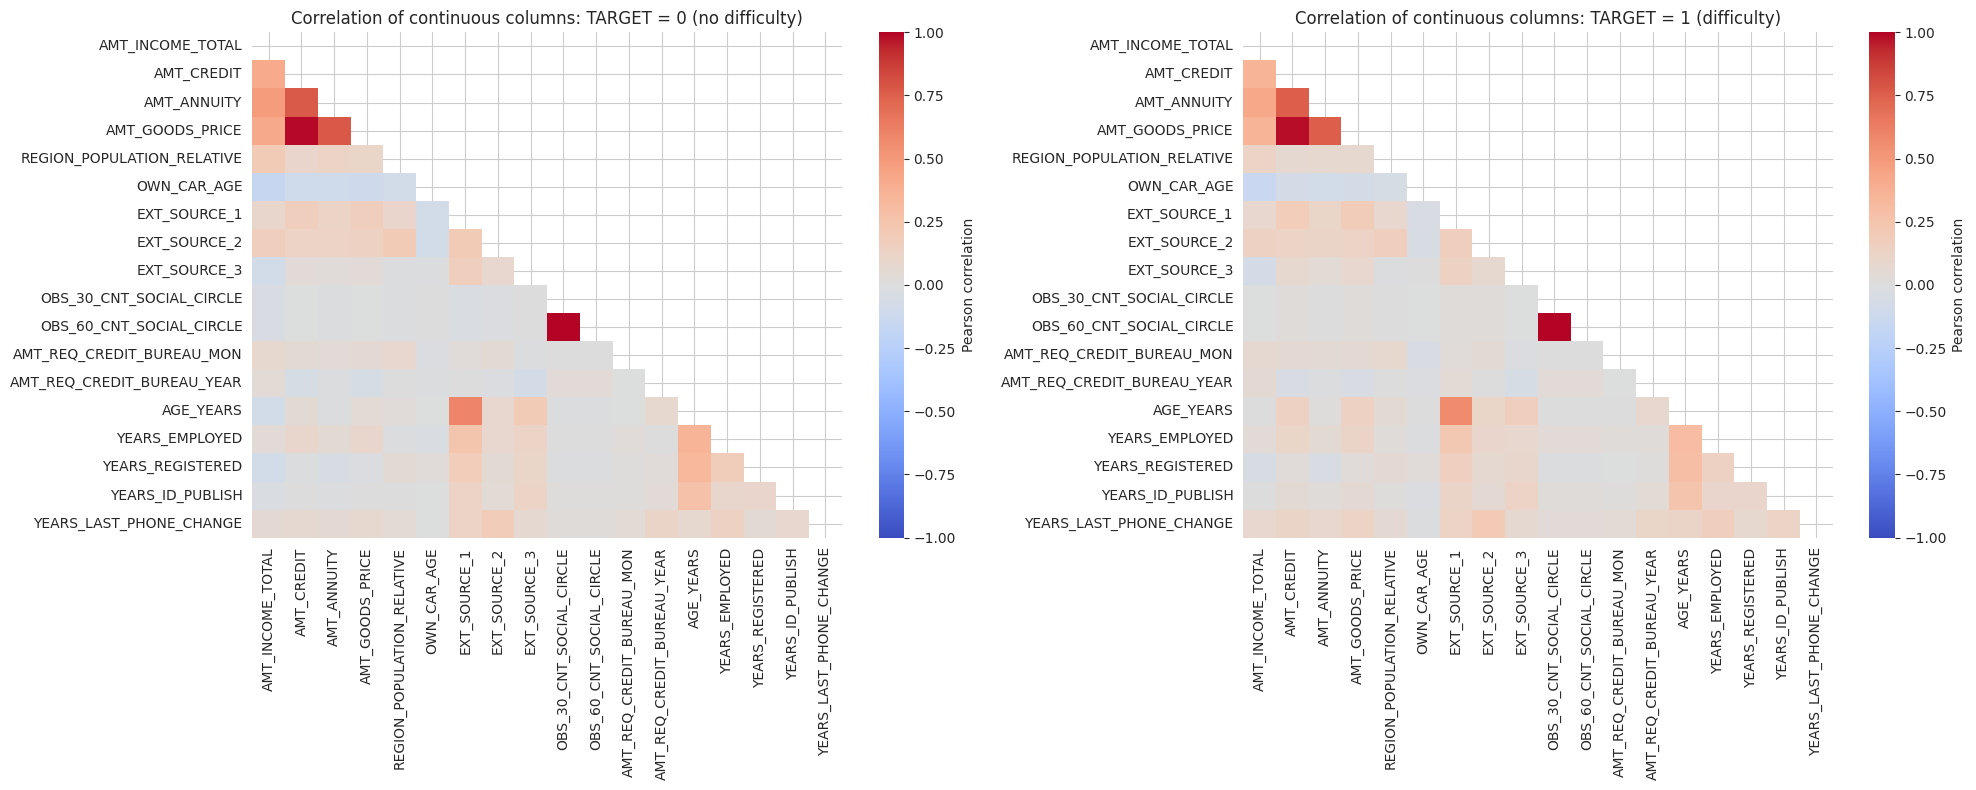

In [ ]:
## Heatmaps

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
mask = np.triu(np.ones_like(corr0, dtype=bool))      # hide the repeated upper half

for ax, corr, title in zip(axes, [corr0, corr1],
                           ["TARGET = 0 (no difficulty)", "TARGET = 1 (difficulty)"]):
    sns.heatmap(corr, mask=mask, cmap="coolwarm", vmin=-1, vmax=1, ax=ax,
                cbar_kws={"label": "Pearson correlation"})
    ax.set_title(f"Correlation of continuous columns: {title}")

plt.tight_layout()
plt.show()

In [ ]:
## Spearman check

sp0 = app_df.loc[app_df["TARGET"] == 0, corr_cols].corr(method="spearman")
sp1 = app_df.loc[app_df["TARGET"] == 1, corr_cols].corr(method="spearman")

print("Spearman, TARGET = 0")
print(top_pairs(sp0).round(3))
print()
print("Spearman, TARGET = 1")
print(top_pairs(sp1).round(3))

Spearman, TARGET = 0
                      var_1                     var_2   corr  abs_corr
0  OBS_30_CNT_SOCIAL_CIRCLE  OBS_60_CNT_SOCIAL_CIRCLE  0.997     0.997
1                AMT_CREDIT           AMT_GOODS_PRICE  0.986     0.986
2                AMT_CREDIT               AMT_ANNUITY  0.832     0.832
3               AMT_ANNUITY           AMT_GOODS_PRICE  0.830     0.830
4              EXT_SOURCE_1                 AGE_YEARS  0.601     0.601
5          AMT_INCOME_TOTAL               AMT_ANNUITY  0.486     0.486
6          AMT_INCOME_TOTAL           AMT_GOODS_PRICE  0.420     0.420
7          AMT_INCOME_TOTAL                AMT_CREDIT  0.416     0.416
8                 AGE_YEARS            YEARS_EMPLOYED  0.308     0.308
9                 AGE_YEARS          YEARS_REGISTERED  0.298     0.298

Spearman, TARGET = 1
                      var_1                     var_2   corr  abs_corr
0  OBS_30_CNT_SOCIAL_CIRCLE  OBS_60_CNT_SOCIAL_CIRCLE  0.997     0.997
1                AMT_CREDIT       

# Close Phase 6

In [ ]:
## Full labels and a count

# Show every label (pandas hides repeated ones)
compare.sort_values("abs_diff", ascending=False).head(10).round(3).reset_index()

,var_1,var_2,corr_0,corr_1,diff,abs_diff
0,AMT_GOODS_PRICE,AGE_YEARS,0.045,0.136,0.091,0.091
1,AMT_CREDIT,AGE_YEARS,0.047,0.135,0.088,0.088
2,AMT_INCOME_TOTAL,AGE_YEARS,-0.079,0.001,0.080,0.080
3,AMT_INCOME_TOTAL,REGION_POPULATION_RELATIVE,0.199,0.121,-0.078,0.078
4,AMT_INCOME_TOTAL,AMT_GOODS_PRICE,0.419,0.353,-0.066,0.066
5,AMT_INCOME_TOTAL,AMT_CREDIT,0.413,0.352,-0.061,0.061
6,AMT_INCOME_TOTAL,AMT_ANNUITY,0.488,0.428,-0.060,0.060
7,AMT_GOODS_PRICE,YEARS_ID_PUBLISH,0.004,0.056,0.052,0.052
8,AMT_CREDIT,YEARS_ID_PUBLISH,0.001,0.052,0.051,0.051
9,AMT_ANNUITY,REGION_POPULATION_RELATIVE,0.121,0.072,-0.049,0.049


In [ ]:
# How many of the shared top 10 pairs are weaker for defaulters?
shared = compare.loc[list(set0 & set1)]
weaker = (shared["corr_1"].abs() < shared["corr_0"].abs()).sum()
print("Pairs weaker in TARGET = 1:", weaker, "of", len(shared))

Pairs weaker in TARGET = 1: 10 of 10


In [ ]:
## The tied columns

check_cols = ["OBS_30_CNT_SOCIAL_CIRCLE", "OBS_60_CNT_SOCIAL_CIRCLE",
              "AMT_REQ_CREDIT_BUREAU_MON", "DEF_30_CNT_SOCIAL_CIRCLE",
              "DEF_60_CNT_SOCIAL_CIRCLE"]

# Share of clients with a value above 0
share_pos = app_df.groupby("TARGET")[check_cols].agg(lambda s: (s.dropna() > 0).mean() * 100)
print("Share with a value above 0 (%)")
print(share_pos.round(2).T)
print()

# Mean on the capped copy, so the 348 value does not dominate
print("Mean (app_clip)")
print(app_clip.groupby("TARGET")[check_cols].mean().round(3).T)
print()

# Goods price had equal medians, so compare means
print(app_df.groupby("TARGET")["AMT_GOODS_PRICE"].mean().round(0))
print()

print(desc[desc["Row"] == "DEF_30_CNT_SOCIAL_CIRCLE"][["Row", "Description"]])

Share with a value above 0 (%)
TARGET                         0      1
OBS_30_CNT_SOCIAL_CIRCLE   46.41  47.76
OBS_60_CNT_SOCIAL_CIRCLE   46.17  47.47
AMT_REQ_CREDIT_BUREAU_MON  16.52  15.67
DEF_30_CNT_SOCIAL_CIRCLE   11.17  14.89
DEF_60_CNT_SOCIAL_CIRCLE    8.16  11.28

Mean (app_clip)
TARGET                         0      1
OBS_30_CNT_SOCIAL_CIRCLE   1.385  1.465
OBS_60_CNT_SOCIAL_CIRCLE   1.369  1.448
AMT_REQ_CREDIT_BUREAU_MON  0.271  0.228
DEF_30_CNT_SOCIAL_CIRCLE   0.139  0.192
DEF_60_CNT_SOCIAL_CIRCLE   0.097  0.138

TARGET
0    542737.0
1    488972.0
Name: AMT_GOODS_PRICE, dtype: float64

                         Row  \
92  DEF_30_CNT_SOCIAL_CIRCLE   

                                                                                  Description  
92  How many observation of client's social surroundings defaulted on 30 DPD (days past due)   


# Phase 7: Previous application data

In [ ]:
## Application level link

prev_link = prev_df.merge(app_df[["SK_ID_CURR", "TARGET"]],
                          on="SK_ID_CURR", how="inner", validate="many_to_one")

print("prev_df rows:", len(prev_df))
print("Rows after merge:", len(prev_link))
print("Unique clients:", prev_link["SK_ID_CURR"].nunique(), "(expected 291,057)")

t = prev_link.groupby("NAME_CONTRACT_STATUS")["TARGET"].agg(["count", "mean"])
t["default_rate"] = (t["mean"] * 100).round(2)
t.drop(columns="mean")

prev_df rows: 1670214
Rows after merge: 1413701
Unique clients: 291057 (expected 291,057)


,count,default_rate
NAME_CONTRACT_STATUS,,
Approved,886099,7.59
Canceled,259441,9.17
Refused,245390,12.00
Unused offer,22771,8.25


In [ ]:
## Client level counts and merge

# Count previous loans per client and outcome
status_counts = pd.crosstab(prev_df["SK_ID_CURR"], prev_df["NAME_CONTRACT_STATUS"])
status_counts.columns = ["PREV_" + c.upper().replace(" ", "_") for c in status_counts.columns]
status_counts["PREV_TOTAL"] = status_counts.sum(axis=1)
status_counts = status_counts.reset_index()

# Left merge keeps all current clients
app_prev = app_df.merge(status_counts, on="SK_ID_CURR", how="left", validate="one_to_one")

print("Rows before:", len(app_df), "| after:", len(app_prev))
print("Duplicate SK_ID_CURR:", app_prev["SK_ID_CURR"].duplicated().sum())

# Flag clients with no previous record
app_prev["HAS_PREV"] = app_prev["PREV_TOTAL"].notna()
print("Clients without a previous record:", (~app_prev["HAS_PREV"]).sum(), "(expected 16,454)")

# For these clients the true number of previous loans is 0
count_cols = [c for c in app_prev.columns if c.startswith("PREV_")]
app_prev[count_cols] = app_prev[count_cols].fillna(0)

Rows before: 307511 | after: 307511
Duplicate SK_ID_CURR: 0
Clients without a previous record: 16454 (expected 16,454)


In [ ]:
## History vs no history

default_rate_table(app_prev, "HAS_PREV")

,n_clients,default_rate,small_group
HAS_PREV,,,
True,291057,8.19,False
False,16454,5.96,False


In [ ]:
## Default rate by number of previous outcomes

hist = app_prev[app_prev["HAS_PREV"]]

for col in ["PREV_REFUSED", "PREV_CANCELED", "PREV_APPROVED", "PREV_UNUSED_OFFER"]:
    band = pd.cut(hist[col], bins=[-1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3 or more"])
    t = hist.groupby(band, observed=True)["TARGET"].agg(["count", "mean"])
    t["default_rate"] = (t["mean"] * 100).round(2)
    print(col)
    print(t.drop(columns="mean"))
    print()

PREV_REFUSED
               count  default_rate
PREV_REFUSED                      
0             190763          7.07
1              46534          8.83
2              22739         10.24
3 or more      31021         12.61

PREV_CANCELED
                count  default_rate
PREV_CANCELED                      
0              180331          7.91
1               50013          8.15
2               26122          8.61
3 or more       34591          9.40

PREV_APPROVED
                count  default_rate
PREV_APPROVED                      
0                 992          8.67
1               76640          9.38
2               67388          8.74
3 or more      146037          7.31

PREV_UNUSED_OFFER
                    count  default_rate
PREV_UNUSED_OFFER                      
0                  272024          8.19
1                   16119          8.06
2                    2332          9.01
3 or more             582          8.08



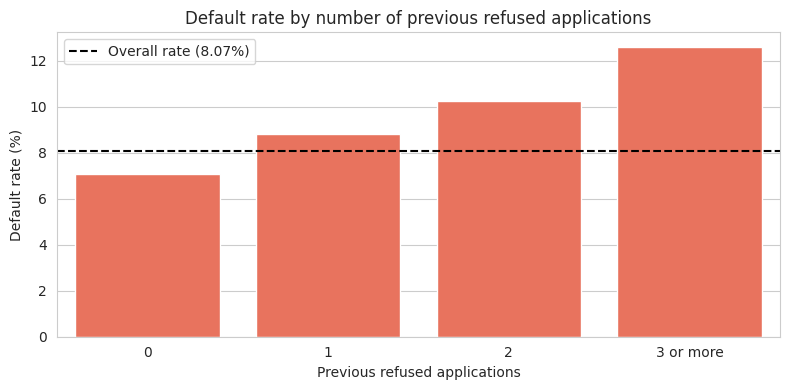

In [ ]:
## Chart for refused count

band = pd.cut(hist["PREV_REFUSED"], bins=[-1, 0, 1, 2, np.inf],
              labels=["0", "1", "2", "3 or more"])
t = hist.groupby(band, observed=True)["TARGET"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=t.index.astype(str), y=t.values, color="tomato", ax=ax)
ax.axhline(overall_rate, color="black", linestyle="--", label=f"Overall rate ({overall_rate:.2f}%)")
ax.set_title("Default rate by number of previous refused applications")
ax.set_xlabel("Previous refused applications")
ax.set_ylabel("Default rate (%)")
ax.legend()
plt.tight_layout()
plt.show()

# # Close Phase 7

In [ ]:
## Control for the number of previous loans

hist = app_prev[app_prev["HAS_PREV"]].copy()
hist["ANY_REFUSED"] = hist["PREV_REFUSED"] > 0

# Compare clients with the same number of previous loans
hist["TOTAL_BAND"] = pd.cut(hist["PREV_TOTAL"], bins=[0, 2, 4, 7, np.inf],
                            labels=["1 to 2", "3 to 4", "5 to 7", "8 or more"])
g = hist.groupby(["TOTAL_BAND", "ANY_REFUSED"], observed=True)["TARGET"]
print("Clients")
print(g.count().unstack())
print()
print("Default rate (%)")
print((g.mean().unstack() * 100).round(2))
print()

# Share of previous applications that were refused
hist["REFUSED_SHARE"] = hist["PREV_REFUSED"] / hist["PREV_TOTAL"]
share_band = pd.cut(hist["REFUSED_SHARE"], bins=[-0.001, 0, 0.25, 0.5, 1],
                    labels=["0%", "up to 25%", "25% to 50%", "above 50%"])
t = hist.groupby(share_band, observed=True)["TARGET"].agg(["count", "mean"])
t["default_rate"] = (t["mean"] * 100).round(2)
print(t.drop(columns="mean"))

Clients
ANY_REFUSED  False  True 
TOTAL_BAND               
1 to 2       92659   5673
3 to 4       53532  19404
5 to 7       33125  30970
8 or more    11447  44247

Default rate (%)
ANY_REFUSED  False  True 
TOTAL_BAND               
1 to 2        7.89  12.09
3 to 4        6.56  10.84
5 to 7        6.10  10.01
8 or more     5.63  10.09

                count  default_rate
REFUSED_SHARE                      
0%             190763          7.07
up to 25%       47397          8.11
25% to 50%      41739         11.33
above 50%       11158         15.93


In [ ]:
## Who has no previous record?

app_prev["IS_PENSIONER"] = app_prev["NAME_INCOME_TYPE"] == "Pensioner"

for col in ["AGE_GROUP", "NAME_CONTRACT_TYPE", "IS_PENSIONER"]:
    g = app_prev.groupby([col, "HAS_PREV"], observed=True)["TARGET"]
    no_hist_share = app_prev.groupby(col, observed=True)["HAS_PREV"].apply(lambda s: (~s).mean() * 100)
    print(col)
    print("Share with no previous record (%)")
    print(no_hist_share.round(2))
    print("Default rate (%): columns are HAS_PREV")
    print((g.mean().unstack() * 100).round(2))
    print("Clients")
    print(g.count().unstack())
    print()

AGE_GROUP
Share with no previous record (%)
AGE_GROUP
Under 30    6.58
30-39       5.24
40-49       4.78
50-59       5.42
60+         5.16
Name: HAS_PREV, dtype: float64
Default rate (%): columns are HAS_PREV
HAS_PREV   False  True 
AGE_GROUP              
Under 30    7.54  11.73
30-39       6.22   9.77
40-49       5.77   7.75
50-59       4.91   6.20
60+         5.28   4.90
Clients
HAS_PREV   False  True 
AGE_GROUP              
Under 30    2959  42041
30-39       4312  77987
40-49       3658  72885
50-59       3688  64386
60+         1837  33758

NAME_CONTRACT_TYPE
Share with no previous record (%)
NAME_CONTRACT_TYPE
Cash loans         4.88
Revolving loans    9.87
Name: HAS_PREV, dtype: float64
Default rate (%): columns are HAS_PREV
HAS_PREV            False  True 
NAME_CONTRACT_TYPE              
Cash loans           6.30   8.45
Revolving loans      4.33   5.60
Clients
HAS_PREV            False   True 
NAME_CONTRACT_TYPE               
Cash loans          13564  264668
Revolving loan

In [ ]:
## Default rate by DEF count

for col in ["DEF_30_CNT_SOCIAL_CIRCLE", "DEF_60_CNT_SOCIAL_CIRCLE"]:
    band = pd.cut(app_df[col], bins=[-1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3 or more"])
    t = app_df.groupby(band, observed=True)["TARGET"].agg(["count", "mean"])
    t["default_rate"] = (t["mean"] * 100).round(2)
    print(col)
    print(t.drop(columns="mean"))
    print()

DEF_30_CNT_SOCIAL_CIRCLE
                           count  default_rate
DEF_30_CNT_SOCIAL_CIRCLE                      
0                         271324          7.78
1                          28328         10.15
2                           5323         11.65
3 or more                   1515         13.00

DEF_60_CNT_SOCIAL_CIRCLE
                           count  default_rate
DEF_60_CNT_SOCIAL_CIRCLE                      
0                         280721          7.83
1                          21841         10.52
2                           3170         12.15
3 or more                    758         14.91



# Phase 8: Research questions and findings

**1. Which client attributes separate defaulters from others?**

**Finding:** External scores, age, job type, and employer type separate them best.

**Evidence:** Score medians are 0.13 to 0.17 lower for defaulters. Default is 11.46% for clients under 30 and 4.92% for clients aged 60 and above. This pattern remains without pensioners, at 11.45% versus 4.46%. The occupation default rate spread is 12.32 percentage points.

**2. Does loan size relative to income raise risk?**

**Finding:** There is no simple link. The default rate rises, then falls.

**Evidence:** Default rates across the five loan-to-income bands are 7.34%, 8.57%, 8.93%, 8.28%, and 7.25%. Contract type and pensioner status do not explain this pattern. The underlying cause remains unknown.

**3. Does previous application history predict default?**

**Finding:** Yes, mainly through previous loan refusals.

**Evidence:** Clients with a 0% refusal share have a 7.07% default rate. Clients with a refusal share above 50% have a 15.93% default rate. The refusal-related default gap is about 4 percentage points across every loan count band.

**4. Do clients with no credit history default more?**

**Finding:** No, not in this dataset.

**Evidence:** Clients without credit history have a 5.96% default rate, compared with 8.19% for clients with credit history. About half of this difference is associated with clients whose previous applications were refused.


**Business Meaning**

**1. Q1: Client Attributes and Default Risk**

Use external scores and key client attributes to group applicants into risk bands and support lending decisions.

**2. Q2: Loan Size Relative to Income**

Do not reject applicants based only on a high loan-to-income ratio. Assess other risk factors before making a decision.

**3. Q3: Previous Application History**

Treat a high previous loan refusal share as a warning sign and review the applicant's risk more carefully.

**4. Q4: Credit History and Default Risk**

Do not reject applicants solely because they have limited credit history. Assess other available information before making a decision.


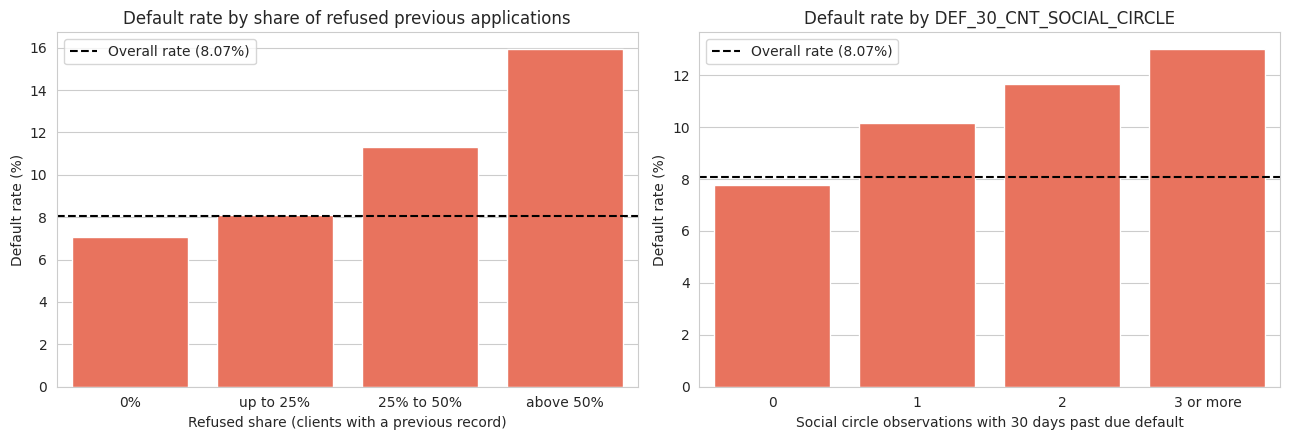

In [ ]:
## Two key charts for the PDF

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Chart 1: default rate by share of refused previous applications
t1 = hist.groupby(share_band, observed=True)["TARGET"].mean() * 100
sns.barplot(x=t1.index.astype(str), y=t1.values, color="tomato", ax=axes[0])
axes[0].axhline(overall_rate, color="black", linestyle="--", label=f"Overall rate ({overall_rate:.2f}%)")
axes[0].set_title("Default rate by share of refused previous applications")
axes[0].set_xlabel("Refused share (clients with a previous record)")
axes[0].set_ylabel("Default rate (%)")
axes[0].legend()

# Chart 2: default rate by DEF_30 count
band = pd.cut(app_df["DEF_30_CNT_SOCIAL_CIRCLE"], bins=[-1, 0, 1, 2, np.inf],
              labels=["0", "1", "2", "3 or more"])
t2 = app_df.groupby(band, observed=True)["TARGET"].mean() * 100
sns.barplot(x=t2.index.astype(str), y=t2.values, color="tomato", ax=axes[1])
axes[1].axhline(overall_rate, color="black", linestyle="--", label=f"Overall rate ({overall_rate:.2f}%)")
axes[1].set_title("Default rate by DEF_30_CNT_SOCIAL_CIRCLE")
axes[1].set_xlabel("Social circle observations with 30 days past due default")
axes[1].set_ylabel("Default rate (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
## Chi-square test and effect size

from scipy.stats import chi2_contingency

rows = []
for col in ["NAME_EDUCATION_TYPE", "OCCUPATION_TYPE", "AGE_GROUP",
            "CODE_GENDER", "NAME_CONTRACT_TYPE", "FLAG_OWN_REALTY"]:
    table = pd.crosstab(app_df[col], app_df["TARGET"])
    chi2, p, dof, expected = chi2_contingency(table)
    n = table.values.sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    rows.append({"column": col, "p_value": p, "cramers_v": round(v, 3),
                 "min_expected_count": round(expected.min(), 1)})

pd.DataFrame(rows).sort_values("cramers_v", ascending=False)

,column,p_value,cramers_v,min_expected_count
1,OCCUPATION_TYPE,0.000000e+00,0.080,42.5
2,AGE_GROUP,0.000000e+00,0.076,2873.5
0,NAME_EDUCATION_TYPE,2.447681e-219,0.058,13.2
3,CODE_GENDER,4.394091e-202,0.055,8481.4
4,NAME_CONTRACT_TYPE,1.023515e-65,0.031,2363.7
5,FLAG_OWN_REALTY,6.681470e-04,0.006,7604.6


# Close Phase 8

In [ ]:
## Print the metrics list in the notebook

metrics_log = pd.DataFrame({
    "metric": ["Mean, median, mode", "Std, variance, range", "IQR and quartiles", "Skewness",
               "Missing percentage", "Duplicate count", "Imbalance ratio", "Class percentages",
               "Default rate per category", "Spread in default rate", "Median gap in IQR units",
               "IQR outlier counts", "Binned default rates", "Pivot table of default rates",
               "Pearson top 10", "Spearman top 10", "Correlation difference between segments",
               "Merge based client rates", "Chi-square test", "Cramer's V", "Baseline accuracy"],
    "cell": [56, 56, "41, 56", "41, 56", 18, 13, 53, 53, 61, 64, 65, 41, 66, 68, 73, 76, 74,
            "80 to 82", 88, 88, 55],
})
print(len(metrics_log), "metrics")
metrics_log

21 metrics


,metric,cell
0,"Mean, median, mode",56
1,"Std, variance, range",56
2,IQR and quartiles,"41, 56"
3,Skewness,"41, 56"
4,Missing percentage,18
5,Duplicate count,13
6,Imbalance ratio,53
7,Class percentages,53
8,Default rate per category,61
9,Spread in default rate,64


In [ ]:
## Final check before submission

# Quick summary of the main objects. Run after "Restart and run all".
print("app_df:", app_df.shape, "| prev_df:", prev_df.shape, "| app_prev:", app_prev.shape)
print("Rows match raw data:", len(app_df) == len(app_raw))
print("TARGET counts:", app_df["TARGET"].value_counts().to_dict())
print("Cleaning log rows:", len(cleaning_log))

app_df: (307511, 79) | prev_df: (1670214, 26) | app_prev: (307511, 86)
Rows match raw data: True
TARGET counts: {0: 282686, 1: 24825}
Cleaning log rows: 12


# Phase 9: Conclusion

## Conclusions

This section explains what we found in simple terms. Every number comes from the analysis in this notebook.

**Key terms**
- **Default rate:** the share of clients who had payment difficulties. The overall default rate is 8.07%, about 1 in 12 clients.
- **Median:** the middle value. Half of the clients are above it and half are below it.
- **Pattern:** two things move together in this data. This does not mean one causes the other.

---

**1. Clients with low outside credit scores have more payment problems.**
- The data has three scores from outside companies (`EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCE_3`). A higher score usually means a safer client.
- Clients with payment problems have a lower middle score on all three. The gap is 0.13 to 0.17 on a scale from 0 to 1.
- `EXT_SOURCE_2` is the easiest to use, because almost every client has this score (only 0.21% are missing).

**2. Younger clients have more payment problems.**
- Clients under 30 have payment problems 11.46% of the time. Clients aged 60 and over have them 4.92% of the time.
- Many older clients are pensioners. We checked without them, and the result stayed the same: 11.45% for under 30 and 4.46% for 60 and over.
- This shows a pattern. It does not mean that age causes payment problems.

**3. Some jobs and employers carry more risk.**
- Low-skill Laborers have payment problems 17.15% of the time. Accountants have them 4.83% of the time.
- Clients who work in transport (type 3) have them 15.75% of the time. Clients in trade (type 6) have them 4.60% of the time.
- These groups are large enough to trust the numbers.

**4. Clients who were refused before have more payment problems.**
- We looked at the share of a client's earlier applications that were refused.
- With no refusals, the rate is 7.07%. With more than half refused, it is 15.93%.
- We also checked clients who had the same number of earlier loans. Clients who were refused still had about 4 points more payment problems. So the result is not just about having many loans.

**5. Late payments among a client's friends and family are a warning sign.**
- One column counts people around the client who were 30 days late on their own loans (`DEF_30_CNT_SOCIAL_CIRCLE`).
- With none, the rate is 7.78%. With one or more, it is 10.15% or higher.
- A related column that counts how many people were checked (`OBS_30_CNT_SOCIAL_CIRCLE`) shows almost no difference.

**6. A big loan compared to income is not a clear warning sign.**
- We compared the loan size with the client's income.
- The rate went up, then down: 7.34%, 8.57%, 8.93%, 8.28%, 7.25%. The clients with the biggest loans compared to income had one of the lowest rates.
- We tried two explanations (loan type and pensioners). Neither worked. We do not know the reason, so we make no claim about it.

**7. Clients with no earlier loans at this company do not have more payment problems.**
- They have payment problems 5.96% of the time. Clients with earlier loans have them 8.19% of the time.
- About half of this gap comes from clients who were refused before.
- This goes against the worry in the business case, which assumed that no history means more risk.

**8. The two client groups look alike when we compare how their columns connect.**
- We checked which columns move together, for clients with and without payment problems.
- The same 10 pairs came out on top in both groups. The biggest difference was small (0.091).
- So the useful signals are in the levels (such as scores and rates), not in how the columns connect.

---

**What we cannot say**
1. **We cannot say what causes payment problems.** We only see patterns.
2. **We cannot say anything about applicants who were turned away.** The data only holds clients whose loan result is known. This matters most for conclusion 7. Clients with no history may look safe here only because risky ones were already refused.
3. **We cannot say anything about credit history at other companies.** The earlier loans in the data are only from this company.
4. **No single category is a strong predictor on its own.** Each one explains only a small part. The signal comes from combining several columns.
5. **Some columns repeat each other.** Loan amount and goods price are almost the same (0.987). Age and the first outside score overlap (0.60). Their effects may be counted twice.

## Recommendations and next steps

Each action below comes from a finding in this analysis. The company has two risks: losing a good client by rejecting them, and losing money by approving a client who will not pay. The actions help with both.

**Key terms**
- **Review flag:** a warning that tells a staff member to look more closely at an application. It does not mean automatic rejection.
- **Risk band:** a group of clients with a similar chance of payment problems, such as low, medium, and high.

---

### Recommended actions

**1. Check the outside credit score first.**
- Use `EXT_SOURCE_2` as a first check. Clients with payment problems have a lower middle score (0.440 vs 0.574).
- Almost every client has this score (only 0.21% are missing), so it works for nearly everyone.

**2. Take a second look at clients who were refused before.**
- If more than 25% of a client's earlier applications were refused, send the application for review.
- Their payment problem rates are 11.33% (25% to 50% refused) and 15.93% (more than 50% refused). The overall rate is 8.07%.

**3. Add a review flag when friends or family were late on payments.**
- Use the columns `DEF_30_CNT_SOCIAL_CIRCLE` and `DEF_60_CNT_SOCIAL_CIRCLE`. Flag the client if either is above 0.
- The payment problem rate goes from about 7.8% to about 10% or higher.

**4. Do not reject a client only because they have no credit history.**
- Clients with no earlier loans at this company have payment problems 5.96% of the time. This is below the overall 8.07%.
- Rejecting them would turn away capable clients.

**5. Do not reject a client only because the loan is large compared to their income.**
- The payment problem rate does not rise as the loan gets bigger compared to income.
- The group with the biggest loans compared to income had one of the lowest rates (7.25%).

**6. Use risk bands, not single rules.**
- No single category column is a strong predictor on its own.
- Combine several signals (score, refusal share, social circle, job type) into one risk band.

**7. Be careful with the highest risk jobs and employers.**
- Low-skill Laborers (17.15%) and clients in transport (type 3) (15.75%) have the highest rates.
- Instead of rejecting them, the company could offer a smaller loan or a higher interest rate. This matches the business goal.

**8. Check the law before using age or gender.**
- Younger clients and men have higher rates (11.46% for under 30, 10.14% for men).
- Rules may not allow these to be used in lending decisions. Ask a legal or compliance team first.

---

### Next steps

**1. Build a prediction model.**
- A model can combine many columns into one risk score.
- Start with the columns that separated the groups: the three outside scores, share of refused applications, `DEF_30` and `DEF_60`, age, and job type.

**2. Use the right way to measure the model.**
- Only 8.07% of clients have payment problems.
- A model that always says "no problems" is right 91.93% of the time, but it finds nobody at risk. So accuracy is not a good measure here.
- Use measures that show how many risky clients the model finds (recall) and how often its warnings are right (precision).

**3. Remove repeated columns.**
- Loan amount (`AMT_CREDIT`) and goods price (`AMT_GOODS_PRICE`) are almost the same (0.987).
- Keep only one of them in the model.

**4. Test combinations.**
- For example, check scores together with age, or refused share together with loan type.
- This notebook did not test these combinations.

**5. Find out why some results happened.**
- We do not know why clients with the biggest loans compared to income have lower rates.
- We also do not know the reason for the part of the "no history" gap that is left after we remove refused clients (1.11 points).

**6. Collect data on rejected applicants if possible.**
- The data only holds clients whose loan result is known.
- With data on rejected applicants, the company could test whether "no history" is really safe, or only looks safe here.

**7. Check the extreme values with the data owner.**
- One income is 117,000,000. One social circle count is 348.
- Ask whether these are entry errors.

**8. Track the results after any change.**
- After the company changes a rule, compare payment problem rates by risk band over time.
- Also track how many capable clients are rejected, so the company does not lose good business.